## Phase 1 — Project Objectives

### Project Title
**Reducing Customer Churn at Meridian Retail Group**

### Project Aim
The aim of this project is to analyse customer purchasing behaviour at Meridian Retail Group, identify patterns associated with customer churn and develop predictive models that can help the business improve customer retention.

### Specific Objectives
1. Measure customer inactivity and determine the extent of customer churn.
2. Examine churn across customer segments, including membership tiers, preferred shopping channels, locations and referral sources.
3. Analyse purchasing behaviour and sales trends to identify patterns associated with customer retention and churn.
4. Examine customer support records to understand whether customer service experiences are associated with churn.
5. Identify customers who may be at risk of churning.
6. Build and compare machine-learning classification models to predict customer churn.
7. Recommend practical strategies Meridian Retail Group can use to improve customer retention and sales performance.

### Expected Outcome
The project is expected to provide evidence-based insights into customer behaviour, highlight potential churn risks and recommend actions that can help Meridian Retail Group strengthen customer relationships and improve retention.

In [ ]:
import os

required_files = [
    "customers.csv",
    "products.csv",
    "orders.csv",
    "order_items.csv",
    "support_tickets.csv"
]

for file in required_files:
    print(file, "✓ Found" if os.path.exists("/content/" + file) else "✗ Missing")

customers.csv ✓ Found
products.csv ✓ Found
orders.csv ✓ Found
order_items.csv ✓ Found
support_tickets.csv ✓ Found


PHASE 2 — Initial inspection


In [ ]:

import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore")

# Load the five datasets
customers = pd.read_csv("/content/customers.csv")
products = pd.read_csv("/content/products.csv")
orders = pd.read_csv("/content/orders.csv")
order_items = pd.read_csv("/content/order_items.csv")
support_tickets = pd.read_csv("/content/support_tickets.csv")

# Store the datasets together for easier inspection
datasets = {
    "Customers": customers,
    "Products": products,
    "Orders": orders,
    "Order Items": order_items,
    "Support Tickets": support_tickets
}

# Display the size and column names of each dataset
for name, df in datasets.items():
    print(f"\n{name}")
    print("Rows and columns:", df.shape)
    print("Column names:", list(df.columns))



Customers
Rows and columns: (6090, 14)
Column names: ['customer_id', 'first_name', 'last_name', 'email', 'phone', 'gender', 'date_of_birth', 'signup_date', 'state', 'city', 'membership_tier', 'preferred_channel', 'marketing_opt_in', 'referral_source']

Products
Rows and columns: (220, 9)
Column names: ['product_id', 'product_name', 'category', 'sub_category', 'brand', 'unit_cost', 'unit_price', 'launch_date', 'is_active']

Orders
Rows and columns: (28297, 9)
Column names: ['order_id', 'customer_id', 'order_date', 'channel', 'order_status', 'payment_method', 'shipping_cost', 'discount_pct', 'total_amount']

Order Items
Rows and columns: (73505, 5)
Column names: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_at_purchase']

Support Tickets
Rows and columns: (5200, 8)
Column names: ['ticket_id', 'customer_id', 'ticket_date', 'issue_category', 'channel', 'resolution_time_hours', 'satisfaction_score', 'ticket_text']


In [ ]:

for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(name.upper())
    print("="*50)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])

    print("\nDuplicate rows:", df.duplicated().sum())



CUSTOMERS

Data types:
customer_id          object
first_name           object
last_name            object
email                object
phone                object
gender               object
date_of_birth        object
signup_date          object
state                object
city                 object
membership_tier      object
preferred_channel    object
marketing_opt_in     object
referral_source      object
dtype: object

Missing values:
email                242
phone                423
date_of_birth        181
city                 121
marketing_opt_in    1191
referral_source     1705
dtype: int64

Duplicate rows: 0

PRODUCTS

Data types:
product_id       object
product_name     object
category         object
sub_category     object
brand            object
unit_cost       float64
unit_price       object
launch_date      object
is_active        object
dtype: object

Missing values:
sub_category    11
dtype: int64

Duplicate rows: 0

ORDERS

Data types:
order_id           object
cus

In [ ]:

# Check whether important ID columns contain duplicates
id_columns = {
    "Customers": (customers, "customer_id"),
    "Products": (products, "product_id"),
    "Orders": (orders, "order_id"),
    "Order Items": (order_items, "order_item_id"),
    "Support Tickets": (support_tickets, "ticket_id")
}

for name, (df, column) in id_columns.items():
    print(f"{name}: {df[column].duplicated().sum()} duplicate {column} values")

# Inspect product prices
print("\nProduct price examples:")
print(products["unit_price"].dropna().head(15).tolist())

# Check unusual numeric values
print("\nOrder numeric summary:")
print(orders[["shipping_cost", "discount_pct", "total_amount"]].describe())

print("\nOrder item numeric summary:")
print(order_items[["quantity", "unit_price_at_purchase"]].describe())

print("\nSupport ticket numeric summary:")
print(support_tickets[
    ["resolution_time_hours", "satisfaction_score"]
].describe())


Customers: 0 duplicate customer_id values
Products: 0 duplicate product_id values
Orders: 25 duplicate order_id values
Order Items: 40 duplicate order_item_id values
Support Tickets: 0 duplicate ticket_id values

Product price examples:
['415.24', '645.92', '$100.91', '70.18', '571.72', '33.47', '540.02', '119.71', '259.81', '304.03', '371.71', '$221.37', '457.4', '172.07', '326.8']

Order numeric summary:
       shipping_cost  discount_pct  total_amount
count   28297.000000  28297.000000  28297.000000
mean        5.294828      3.485352   1541.876389
std         4.516316      6.380998   1174.373886
min       -12.990000      0.000000      7.070000
25%         0.000000      0.000000    671.230000
50%         4.990000      0.000000   1265.840000
75%         7.990000      5.000000   2125.780000
max        12.990000     25.000000  10536.770000

Order item numeric summary:
           quantity  unit_price_at_purchase
count  73505.000000            72036.000000
mean       1.553663             

In [ ]:

# Inspect duplicate order IDs
print("DUPLICATE ORDER RECORDS")
print(
    orders[orders.duplicated(subset=["order_id"], keep=False)]
    .sort_values("order_id")
    .head(20)
)

# Inspect duplicate order item IDs
print("\nDUPLICATE ORDER ITEM RECORDS")
print(
    order_items[
        order_items.duplicated(subset=["order_item_id"], keep=False)
    ]
    .sort_values("order_item_id")
    .head(20)
)

# Inspect negative shipping costs
print("\nNEGATIVE SHIPPING COSTS")
print(orders[orders["shipping_cost"] < 0].head(10))

# Inspect negative quantities
print("\nNEGATIVE QUANTITIES")
print(order_items[order_items["quantity"] < 0].head(10))

# Inspect negative resolution times
print("\nNEGATIVE RESOLUTION TIMES")
print(
    support_tickets[
        support_tickets["resolution_time_hours"] < 0
    ]
)

# Inspect unusually long resolution times
print("\nLONG RESOLUTION TIMES (OVER 168 HOURS)")
print(
    support_tickets[
        support_tickets["resolution_time_hours"] > 168
    ].sort_values("resolution_time_hours", ascending=False).head(10)
)


DUPLICATE ORDER RECORDS
        order_id customer_id  order_date     channel order_status  \
2873   ORD102482  CUST005630  2025-03-17  Mobile App    Completed   
10265  ORD102482  CUST005630  2025-03-17  Mobile App    Completed   
19831  ORD103359  CUST005402  2025-05-29    In-Store    Completed   
15944  ORD103359  CUST005402  2025-05-29    In-Store    Completed   
5795   ORD103787  CUST001807  2026-02-06  Mobile App    Completed   
23352  ORD103787  CUST001807  2026-02-06  Mobile App    Completed   
20404  ORD103914  CUST005431  2024-12-12    In-Store    Completed   
17094  ORD103914  CUST005431  2024-12-12    In-Store    Completed   
14105  ORD104413  CUST004015  2024-09-11  Mobile App    Completed   
19106  ORD104413  CUST004015  2024-09-11  Mobile App    Completed   
20621  ORD104809  CUST005324  2025-08-05  Mobile App    Completed   
5870   ORD104809  CUST005324  2025-08-05  Mobile App    Completed   
25118  ORD107269  CUST004048  2022-08-10    In-Store    Completed   
17931  ORD

In [ ]:

# Check whether repeated order IDs have identical records
order_duplicate_check = (
    orders.groupby("order_id")
    .filter(lambda group: len(group) > 1)
    .groupby("order_id")
    .nunique()
)

print("ORDER ID DUPLICATE CHECK")
print("Number of repeated order IDs:", len(order_duplicate_check))
print("Repeated IDs with conflicting values:",
      (order_duplicate_check > 1).any(axis=1).sum())

# Check whether repeated order item IDs have identical records
item_duplicate_check = (
    order_items.groupby("order_item_id")
    .filter(lambda group: len(group) > 1)
    .groupby("order_item_id")
    .nunique()
)

print("\nORDER ITEM ID DUPLICATE CHECK")
print("Number of repeated item IDs:", len(item_duplicate_check))
print("Repeated IDs with conflicting values:",
      (item_duplicate_check > 1).any(axis=1).sum())


ORDER ID DUPLICATE CHECK
Number of repeated order IDs: 25
Repeated IDs with conflicting values: 0

ORDER ITEM ID DUPLICATE CHECK
Number of repeated item IDs: 40
Repeated IDs with conflicting values: 0


In [ ]:

# Create working copies of the original datasets
customers_clean = customers.copy()
products_clean = products.copy()
orders_clean = orders.copy()
order_items_clean = order_items.copy()
support_tickets_clean = support_tickets.copy()

# Remove verified duplicate records
orders_clean = orders_clean.drop_duplicates(
    subset="order_id",
    keep="first"
)

order_items_clean = order_items_clean.drop_duplicates(
    subset="order_item_id",
    keep="first"
)

# Confirm the cleaning results
print("CLEANING SUMMARY")

for name, df in {
    "Customers": customers_clean,
    "Products": products_clean,
    "Orders": orders_clean,
    "Order Items": order_items_clean,
    "Support Tickets": support_tickets_clean
}.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

print("\nRemaining duplicate order IDs:",
      orders_clean["order_id"].duplicated().sum())

print("Remaining duplicate order item IDs:",
      order_items_clean["order_item_id"].duplicated().sum())


CLEANING SUMMARY
Customers: 6090 rows, 14 columns
Products: 220 rows, 9 columns
Orders: 28272 rows, 9 columns
Order Items: 73465 rows, 5 columns
Support Tickets: 5200 rows, 8 columns

Remaining duplicate order IDs: 0
Remaining duplicate order item IDs: 0


In [ ]:

# 1. Convert date columns to proper datetime format
date_columns = {
    "customers": (customers_clean, "signup_date"),
    "products": (products_clean, "launch_date"),
    "orders": (orders_clean, "order_date"),
    "support_tickets": (support_tickets_clean, "ticket_date")
}

for name, (df, column) in date_columns.items():
    df[column] = pd.to_datetime(df[column], errors="coerce")

# Also convert customers' date of birth
customers_clean["date_of_birth"] = pd.to_datetime(
    customers_clean["date_of_birth"], errors="coerce"
)

# 2. Convert product unit prices from text to numeric
products_clean["unit_price"] = pd.to_numeric(
    products_clean["unit_price"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# 3. Treat negative resolution times as invalid missing values
negative_resolution_count = (
    support_tickets_clean["resolution_time_hours"] < 0
).sum()

support_tickets_clean.loc[
    support_tickets_clean["resolution_time_hours"] < 0,
    "resolution_time_hours"
] = np.nan

# 4. Report the changes
print("DATE AND NUMERIC CLEANING SUMMARY")

for name, (df, column) in date_columns.items():
    print(f"{name}: {column} converted to datetime")
    print("Missing or invalid dates:", df[column].isna().sum())

print("\nProduct unit price data type:",
      products_clean["unit_price"].dtype)
print("Missing product prices:",
      products_clean["unit_price"].isna().sum())

print("\nNegative resolution times changed to missing:",
      negative_resolution_count)


DATE AND NUMERIC CLEANING SUMMARY
customers: signup_date converted to datetime
Missing or invalid dates: 487
products: launch_date converted to datetime
Missing or invalid dates: 0
orders: order_date converted to datetime
Missing or invalid dates: 424
support_tickets: ticket_date converted to datetime
Missing or invalid dates: 0

Product unit price data type: Float64
Missing product prices: 0

Negative resolution times changed to missing: 6


In [ ]:

clean_datasets = {
    "Customers": customers_clean,
    "Products": products_clean,
    "Orders": orders_clean,
    "Order Items": order_items_clean,
    "Support Tickets": support_tickets_clean
}

for name, df in clean_datasets.items():
    print(f"\n{name}")
    missing = df.isnull().sum()
    print(missing[missing > 0].sort_values(ascending=False))



Customers
referral_source     1705
marketing_opt_in    1191
signup_date          487
phone                423
email                242
date_of_birth        181
city                 121
dtype: int64

Products
sub_category    11
dtype: int64

Orders
order_date    424
dtype: int64

Order Items
unit_price_at_purchase    1469
dtype: int64

Support Tickets
satisfaction_score       592
resolution_time_hours      6
dtype: int64


### Phase 2 — Initial Data Inspection Summary

The five datasets were successfully loaded and inspected.

The datasets contain 6,090 customer records, 220 product records, 28,297 original order records, 73,505 original order-item records and 5,200 support-ticket records.

The initial inspection identified missing values, duplicate identifiers, inconsistent data types and unusual numerical values. Notable issues included missing customer information, missing order dates, missing purchase prices, negative quantities, negative shipping costs and invalid support resolution times.

These findings provided the basis for the subsequent data-cleaning and preparation process.

In [ ]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import joblib

DATA_DIR = "/content"
files = {
    "customers": "customers.csv", "products": "products.csv",
    "orders": "orders.csv", "order_items": "order_items.csv",
    "support_tickets": "support_tickets.csv"
}
def load_file(filename):
    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Upload {filename} to the Colab session.")
    return pd.read_csv(path)

customers, products, orders, order_items, support_tickets = [
    load_file(files[k]) for k in files
]
for name, df in zip(files, [customers, products, orders, order_items, support_tickets]):
    print(name, df.shape)


FileNotFoundError: Upload customers.csv to the Colab session.

## Phase 3 — Data Cleaning and Preparation

This phase focuses on improving the quality and consistency of the five datasets before analysis. The process includes removing verified duplicate records, correcting data types, standardising categorical values, investigating invalid entries and addressing missing values.

The original datasets are preserved, while separate working copies are used for cleaning to maintain data integrity.

In [100]:
def clean_text(s):
    return s.astype("string").str.strip()

def parse_dates(df, columns):
    for col in columns:
        if col in df:
            df[col] = pd.to_datetime(df[col], errors="coerce")
    return df

for df in datasets.values():
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = clean_text(df[col])

customers = parse_dates(customers, ["signup_date", "date_of_birth"])
orders = parse_dates(orders, ["order_date"])
products = parse_dates(products, ["launch_date"])
support_tickets = parse_dates(support_tickets, ["ticket_date"])

for col in ["unit_price", "unit_cost"]:
    if col in products:
        products[col] = pd.to_numeric(products[col].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
for col in ["total_amount", "shipping_cost"]:
    if col in orders:
        orders[col] = pd.to_numeric(orders[col].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
if "unit_price_at_purchase" in order_items:
    order_items["unit_price_at_purchase"] = pd.to_numeric(order_items["unit_price_at_purchase"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
if "quantity" in order_items:
    order_items["quantity"] = pd.to_numeric(order_items["quantity"], errors="coerce").abs()

customers = customers.drop_duplicates()
products = products.drop_duplicates()
orders = orders.drop_duplicates()
order_items = order_items.drop_duplicates()
support_tickets = support_tickets.drop_duplicates()

line_key = ["order_id", "product_id", "quantity", "unit_price_at_purchase"]
if set(line_key).issubset(order_items.columns):
    order_items = order_items.drop_duplicates(subset=line_key)

if "membership_tier" in customers:
    customers["membership_tier"] = customers["membership_tier"].str.title()
if "order_status" in orders:
    orders["order_status"] = orders["order_status"].str.title().str.strip()
if "marketing_opt_in" in customers:
    customers["marketing_opt_in"] = customers["marketing_opt_in"].str.lower().map(
        {"y":"Yes","yes":"Yes","1":"Yes","n":"No","no":"No","0":"No"}
    )


In [ ]:

print("NEGATIVE SHIPPING COSTS")
print("Count:", (orders_clean["shipping_cost"] < 0).sum())
print(orders_clean.loc[
    orders_clean["shipping_cost"] < 0,
    ["order_id", "order_status", "shipping_cost"]
])

print("\nNEGATIVE ITEM QUANTITIES")
print("Count:", (order_items_clean["quantity"] < 0).sum())
print(order_items_clean.loc[
    order_items_clean["quantity"] < 0,
    ["order_item_id", "order_id", "product_id", "quantity"]
])

print("\nORDER STATUS COUNTS")
print(orders_clean["order_status"].value_counts(dropna=False))


NEGATIVE SHIPPING COSTS
Count: 8
        order_id order_status  shipping_cost
5726   ORD122262    Completed          -7.99
7646   ORD111109    Completed          -7.99
9998   ORD102713    Completed          -4.99
12212  ORD120435    Completed         -12.99
12339  ORD120830    Completed         -12.99
12600  ORD123636    Completed          -5.99
19012  ORD109864    Completed          -4.99
25906  ORD112579    Completed          -7.99

NEGATIVE ITEM QUANTITIES
Count: 18
      order_item_id   order_id product_id  quantity
4209       OI510461  ORD127669   PROD1119        -4
5687       OI552598  ORD116292   PROD1114        -3
6925       OI547959  ORD104939   PROD1140        -1
8832       OI560051  ORD127656   PROD1173        -1
12567      OI520771  ORD112931   PROD1203        -1
22410      OI532150  ORD126741   PROD1101        -3
22789      OI500334  ORD127627   PROD1194        -1
29496      OI503467  ORD119668   PROD1073        -1
39951      OI521929  ORD121945   PROD1085        -1
41848 

In [ ]:

# Link negative-quantity records to their order details
negative_items = order_items_clean[
    order_items_clean["quantity"] < 0
].merge(
    orders_clean[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

print("NEGATIVE QUANTITIES BY ORDER STATUS")
print(negative_items["order_status"].value_counts(dropna=False))

print("\nDETAILS OF NEGATIVE-QUANTITY ORDERS")
print(
    negative_items[
        ["order_item_id", "order_id", "product_id",
         "quantity", "order_status"]
    ].to_string(index=False)
)


NEGATIVE QUANTITIES BY ORDER STATUS
order_status
Completed    17
Returned      1
Name: count, dtype: int64

DETAILS OF NEGATIVE-QUANTITY ORDERS
order_item_id  order_id product_id  quantity order_status
     OI510461 ORD127669   PROD1119        -4    Completed
     OI552598 ORD116292   PROD1114        -3    Completed
     OI547959 ORD104939   PROD1140        -1    Completed
     OI560051 ORD127656   PROD1173        -1    Completed
     OI520771 ORD112931   PROD1203        -1     Returned
     OI532150 ORD126741   PROD1101        -3    Completed
     OI500334 ORD127627   PROD1194        -1    Completed
     OI503467 ORD119668   PROD1073        -1    Completed
     OI521929 ORD121945   PROD1085        -1    Completed
     OI510375 ORD112903   PROD1180        -1    Completed
     OI534040 ORD100650   PROD1142        -2    Completed
     OI501248 ORD112306   PROD1147        -3    Completed
     OI549969 ORD109797   PROD1023        -4    Completed
     OI564623 ORD125447   PROD1143        -4

In [ ]:

orders_clean["order_status"] = (
    orders_clean["order_status"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print(orders_clean["order_status"].value_counts(dropna=False))


order_status
COMPLETED    25481
RETURNED      1230
CANCELLED      976
PENDING        585
Name: count, dtype: Int64


In [ ]:
negative_order_details = negative_items.merge(
    orders_clean[
        ["order_id", "order_date", "total_amount", "shipping_cost"]
    ],
    on="order_id",
    how="left"
)

print(
    negative_order_details[
        [
            "order_id",
            "order_date",
            "order_status",
            "quantity",
            "total_amount",
            "shipping_cost"
        ]
    ].to_string(index=False)
)

 order_id order_date order_status  quantity  total_amount  shipping_cost
ORD127669 2025-10-28    Completed        -4       3473.59           4.99
ORD116292 2026-05-30    Completed        -3       3163.23           7.99
ORD104939 2023-03-09    Completed        -1       1778.52           0.00
ORD127656 2025-05-25    Completed        -1       4636.99           7.99
ORD112931 2025-01-27     Returned        -1        314.64           7.99
ORD126741 2024-08-13    Completed        -3       3031.92           0.00
ORD127627 2026-02-21    Completed        -1       1250.02           0.00
ORD119668 2024-10-31    Completed        -1       2041.45           4.99
ORD121945 2025-08-27    Completed        -1       2702.50           5.99
ORD112903 2026-06-27    Completed        -1        799.68           7.99
ORD100650 2023-10-19    Completed        -2        527.22           0.00
ORD112306 2023-10-16    Completed        -3        832.96          12.99
ORD109797 2024-03-31    Completed        -4       2

In [ ]:
negative_shipping = orders_clean[
    orders_clean["shipping_cost"] < 0
]

print("Number of negative shipping costs:",
      len(negative_shipping))

print(
    negative_shipping[
        ["order_id", "order_status", "shipping_cost"]
    ].to_string(index=False)
)

Number of negative shipping costs: 8
 order_id order_status  shipping_cost
ORD122262    COMPLETED          -7.99
ORD111109    COMPLETED          -7.99
ORD102713    COMPLETED          -4.99
ORD120435    COMPLETED         -12.99
ORD120830    COMPLETED         -12.99
ORD123636    COMPLETED          -5.99
ORD109864    COMPLETED          -4.99
ORD112579    COMPLETED          -7.99


In [ ]:
negative_shipping_count = (
    orders_clean["shipping_cost"] < 0
).sum()

orders_clean.loc[
    orders_clean["shipping_cost"] < 0,
    "shipping_cost"
] = np.nan

print("Invalid shipping costs corrected:",
      negative_shipping_count)

print("Remaining negative shipping costs:",
      (orders_clean["shipping_cost"] < 0).sum())

print("Missing shipping costs:",
      orders_clean["shipping_cost"].isna().sum())

Invalid shipping costs corrected: 8
Remaining negative shipping costs: 0
Missing shipping costs: 8


In [ ]:
categorical_columns = {
    "customers": (customers_clean, [
        "gender", "state", "city", "membership_tier",
        "preferred_channel", "marketing_opt_in", "referral_source"
    ]),
    "products": (products_clean, [
        "category", "sub_category", "brand", "is_active"
    ]),
    "orders": (orders_clean, [
        "channel", "order_status", "payment_method"
    ]),
    "support_tickets": (support_tickets_clean, [
        "issue_category", "channel"
    ])
}

for name, (df, columns) in categorical_columns.items():
    for column in columns:
        df[column] = df[column].astype("string").str.strip()
        df[column] = df[column].replace("", pd.NA)

print("Categorical values trimmed and empty strings standardised.")

Categorical values trimmed and empty strings standardised.


In [ ]:
print("MEMBERSHIP TIERS")
print(customers_clean["membership_tier"].value_counts(dropna=False))

print("\nGENDER")
print(customers_clean["gender"].value_counts(dropna=False))

print("\nMARKETING OPT-IN")
print(customers_clean["marketing_opt_in"].value_counts(dropna=False))

MEMBERSHIP TIERS
membership_tier
bronze      944
BRONZE      939
Bronze      902
silver      606
SILVER      596
Silver      566
gold        394
GOLD        385
Gold        347
platinum    142
PLATINUM    139
Platinum    130
Name: count, dtype: Int64

GENDER
gender
M        2530
F        2363
Other    1197
Name: count, dtype: Int64

MARKETING OPT-IN
marketing_opt_in
Y       1249
N       1208
<NA>    1191
0        623
no       615
yes      612
1        592
Name: count, dtype: Int64


In [ ]:
# Standardise membership tiers
customers_clean["membership_tier"] = (
    customers_clean["membership_tier"].str.title()
)

# Standardise marketing opt-in values
marketing_mapping = {
    "Y": "Yes",
    "yes": "Yes",
    "1": "Yes",
    "N": "No",
    "no": "No",
    "0": "No"
}

customers_clean["marketing_opt_in"] = (
    customers_clean["marketing_opt_in"]
    .map(marketing_mapping)
    .astype("string")
)

# Check the results
print("MEMBERSHIP TIERS")
print(customers_clean["membership_tier"].value_counts(dropna=False))

print("\nMARKETING OPT-IN")
print(customers_clean["marketing_opt_in"].value_counts(dropna=False))

MEMBERSHIP TIERS
membership_tier
Bronze      2785
Silver      1768
Gold        1126
Platinum     411
Name: count, dtype: Int64

MARKETING OPT-IN
marketing_opt_in
Yes     2453
No      2446
<NA>    1191
Name: count, dtype: Int64


In [ ]:
columns_to_check = {
    "Product category": products_clean["category"],
    "Product sub-category": products_clean["sub_category"],
    "Product brand": products_clean["brand"],
    "Product active status": products_clean["is_active"],
    "Order channel": orders_clean["channel"],
    "Payment method": orders_clean["payment_method"],
    "Support issue category": support_tickets_clean["issue_category"],
    "Support channel": support_tickets_clean["channel"]
}

for name, column in columns_to_check.items():
    print(f"\n{name}")
    print(column.value_counts(dropna=False))


Product category
category
Electronics               48
Beauty & Personal Care    45
Home & Kitchen            45
Sports & Outdoors         44
Apparel                   38
Name: count, dtype: Int64

Product sub-category
sub_category
Small Appliances     16
Cycling              16
Camping              13
Wellness             12
Smart Home           12
Accessories          12
Fragrance            11
<NA>                 11
Bedding              10
Haircare             10
Smartphones          10
Women's Clothing      9
Skincare              9
Furniture             8
Cameras               8
Men's Clothing        8
Footwear              8
Cookware              7
Team Sports           7
Headphones            7
Fitness Equipment     6
Tablets               4
Decor                 3
Laptops               3
Name: count, dtype: Int64

Product brand
brand
Amberly            19
Orion              18
Pinecrest          17
Nova               17
BrightPath         17
Northfield         17
Lumen       

In [ ]:
for name, df in datasets.items():
    clean_df = globals()[name.lower().replace(" ", "_") + "_clean"]

    print(f"\n{name}")
    missing = clean_df.isnull().sum()
    print(missing[missing > 0])


Customers
email                242
phone                423
date_of_birth        181
signup_date          487
city                 121
marketing_opt_in    1191
referral_source     1705
dtype: int64

Products
sub_category    11
dtype: int64

Orders
order_date       424
shipping_cost      8
dtype: int64

Order Items
unit_price_at_purchase    1469
dtype: int64

Support Tickets
resolution_time_hours      6
satisfaction_score       592
dtype: int64


In [ ]:
missing_purchase_prices = order_items_clean[
    order_items_clean["unit_price_at_purchase"].isna()
]

print("Missing purchase prices:",
      len(missing_purchase_prices))

print("\nSample records:")
print(
    missing_purchase_prices.head(10).to_string(index=False)
)

print("\nQuantity distribution:")
print(
    missing_purchase_prices["quantity"].value_counts(dropna=False)
)

Missing purchase prices: 1469

Sample records:
order_item_id  order_id product_id  quantity  unit_price_at_purchase
     OI569419 ORD102651   PROD1005         1                     NaN
     OI531728 ORD127958   PROD1151         2                     NaN
     OI544989 ORD124532   PROD1215         2                     NaN
     OI519950 ORD113760   PROD1061         4                     NaN
     OI528560 ORD109265   PROD1203         1                     NaN
     OI504529 ORD105792   PROD1070         4                     NaN
     OI571598 ORD114045   PROD1179         1                     NaN
     OI557889 ORD114054   PROD1155         1                     NaN
     OI560979 ORD120654   PROD1154         1                     NaN
     OI515145 ORD120558   PROD1077         1                     NaN

Quantity distribution:
quantity
1    950
2    291
3    145
4     83
Name: count, dtype: int64


In [ ]:
missing_price_products = missing_purchase_prices.merge(
    products_clean[["product_id", "product_name", "unit_price"]],
    on="product_id",
    how="left"
)

print("Missing purchase-price records:", len(missing_price_products))

print("\nRecords with available catalogue prices:",
      missing_price_products["unit_price"].notna().sum())

print("Records without catalogue prices:",
      missing_price_products["unit_price"].isna().sum())

print("\nSample comparison:")
print(
    missing_price_products[
        ["product_id", "product_name", "quantity", "unit_price"]
    ].head(10).to_string(index=False)
)

Missing purchase-price records: 1469

Records with available catalogue prices: 1469
Records without catalogue prices: 0

Sample comparison:
product_id                    product_name  quantity  unit_price
  PROD1005           Orion Smartphone Plus         1       33.47
  PROD1151             Sabre Headphone Pro         2      492.04
  PROD1215 Northfield Women's Clothing Pro         2      148.05
  PROD1061         Meridian Basics Cycling         4      190.36
  PROD1203              Amberly Footwear X         1      208.13
  PROD1070    Meridian Basics Bedding Plus         4      646.12
  PROD1179   Meridian Basics Wellness Lite         1      814.08
  PROD1155        BrightPath Skincare Lite         1      252.11
  PROD1154            Crestline Decor Plus         1      544.11
  PROD1077   TrueForm Women's Clothing Max         1      655.79


In [ ]:
missing_price_status = missing_price_products.merge(
    orders_clean[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

print("Missing purchase prices by order status:")
print(
    missing_price_status["order_status"]
    .value_counts(dropna=False)
)

Missing purchase prices by order status:
order_status
COMPLETED    1313
RETURNED       69
CANCELLED      46
PENDING        41
Name: count, dtype: Int64


In [ ]:
missing_satisfaction = support_tickets_clean[
    support_tickets_clean["satisfaction_score"].isna()
]

print("Missing satisfaction scores:",
      len(missing_satisfaction))

print("\nMissing scores by issue category:")
print(
    missing_satisfaction["issue_category"]
    .value_counts(dropna=False)
)

print("\nMissing scores by support channel:")
print(
    missing_satisfaction["channel"]
    .value_counts(dropna=False)
)

Missing satisfaction scores: 592

Missing scores by issue category:
issue_category
Return Request        92
Damaged Item          78
Product Question      74
Billing Issue         73
Refund Status         73
Wrong Item Shipped    72
Delivery Delay        68
Account Access        62
Name: count, dtype: Int64

Missing scores by support channel:
channel
Social Media    159
Live Chat       147
Email           144
Phone           142
Name: count, dtype: Int64


In [ ]:
missing_signup = customers_clean[
    customers_clean["signup_date"].isna()
]

print("Missing signup dates:", len(missing_signup))

print("\nSample affected customers:")
print(
    missing_signup[
        ["customer_id", "membership_tier", "preferred_channel"]
    ].head(10).to_string(index=False)
)

Missing signup dates: 487

Sample affected customers:
customer_id membership_tier preferred_channel
 CUST005168          Bronze            Online
 CUST004228          Bronze          In-Store
 CUST004964            Gold        Mobile App
 CUST002853          Silver          In-Store
 CUST005006          Silver            Online
 CUST000012          Silver          In-Store
 CUST000138          Bronze        Mobile App
 CUST002142          Bronze            Online
 CUST004134          Bronze          In-Store
 CUST002552          Silver        Mobile App


In [ ]:
missing_order_dates = orders_clean[
    orders_clean["order_date"].isna()
]

print("Missing order dates:", len(missing_order_dates))

print("\nOrder status distribution:")
print(
    missing_order_dates["order_status"]
    .value_counts(dropna=False)
)

print("\nSample affected orders:")
print(
    missing_order_dates[
        ["order_id", "customer_id", "order_status", "total_amount"]
    ].head(10).to_string(index=False)
)

Missing order dates: 424

Order status distribution:
order_status
COMPLETED    384
RETURNED      16
PENDING       14
CANCELLED     10
Name: count, dtype: Int64

Sample affected orders:
 order_id customer_id order_status  total_amount
ORD119703  CUST003480    COMPLETED       1483.08
ORD102895  CUST003791    COMPLETED       1836.57
ORD101053  CUST003641    COMPLETED       1326.77
ORD119231  CUST005663     RETURNED       2387.41
ORD126573  CUST003678    CANCELLED       1225.95
ORD115857  CUST005615    CANCELLED       5026.81
ORD126367  CUST004904    COMPLETED         26.30
ORD114173  CUST004542    COMPLETED        887.58
ORD113748  CUST001315    COMPLETED        523.86
ORD126350  CUST000469    COMPLETED       5921.00


In [ ]:
print("Resolution time summary:")
print(support_tickets_clean["resolution_time_hours"].describe())

print("\nHighest resolution times:")
print(
    support_tickets_clean.nlargest(
        10, "resolution_time_hours"
    )[
        ["ticket_id", "issue_category", "resolution_time_hours"]
    ].to_string(index=False)
)

Resolution time summary:
count    5194.000000
mean       18.478244
std        25.012761
min         0.000000
25%         5.200000
50%        12.200000
75%        24.700000
max       782.000000
Name: resolution_time_hours, dtype: float64

Highest resolution times:
ticket_id     issue_category  resolution_time_hours
TIX101422      Billing Issue                  782.0
TIX100854      Billing Issue                  682.0
TIX100190     Account Access                  542.0
TIX103752 Wrong Item Shipped                  374.0
TIX100781   Product Question                  312.0
TIX101109     Delivery Delay                  230.0
TIX104878      Refund Status                  222.0
TIX102542   Product Question                  139.2
TIX102992     Delivery Delay                  134.2
TIX105172     Account Access                  125.8


In [ ]:
print(
    "Tickets with zero resolution time:",
    (support_tickets_clean["resolution_time_hours"] == 0).sum()
)

Tickets with zero resolution time: 18


In [ ]:
print("SATISFACTION SCORE")
print(support_tickets_clean["satisfaction_score"].describe())

print("\nDISCOUNT PERCENTAGE")
print(orders_clean["discount_pct"].describe())

print("\nPURCHASE PRICE")
print(order_items_clean["unit_price_at_purchase"].describe())

print("\nORDER TOTAL")
print(orders_clean["total_amount"].describe())

SATISFACTION SCORE
count    4608.000000
mean        3.893229
std         1.167302
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: satisfaction_score, dtype: float64

DISCOUNT PERCENTAGE
count    28272.000000
mean         3.486135
std          6.382363
min          0.000000
25%          0.000000
50%          0.000000
75%          5.000000
max         25.000000
Name: discount_pct, dtype: float64

PURCHASE PRICE
count    71996.000000
mean       394.561329
std        262.007235
min          8.790000
25%        174.677500
50%        356.610000
75%        621.125000
max       1027.760000
Name: unit_price_at_purchase, dtype: float64

ORDER TOTAL
count    28272.000000
mean      1541.830708
std       1174.483853
min          7.070000
25%        671.415000
50%       1265.720000
75%       2125.372500
max      10536.770000
Name: total_amount, dtype: float64


### Phase 3 — Data Cleaning and Preparation Summary

The five datasets were cleaned using separate working copies to preserve the original data.

The cleaning process included:

1. Removing 25 verified duplicate order records and 40 verified duplicate order-item records.
2. Converting date columns to appropriate datetime formats and cleaning the product catalogue price field.
3. Standardising inconsistent membership-tier and marketing opt-in values.
4. Removing unnecessary spaces from categorical values and converting empty strings to missing values.
5. Replacing six negative support resolution times and eight negative shipping costs with missing values.
6. Investigating 18 negative item quantities and retaining them for further investigation.
7. Investigating missing values in customer, product, order, order-item and support-ticket records. Missing values were retained where reliable replacement information was unavailable.
8. Reviewing unusually high and zero support resolution times without automatically deleting potentially valid records.
9. Checking satisfaction scores, discount percentages, purchase prices and order totals for invalid numerical values.

The cleaning process improved the consistency and reliability of the datasets while preserving records that may still provide useful information for analysis.

Some missing values and unusual observations remain documented for appropriate handling during subsequent analysis.

In [ ]:
import sqlite3
conn = sqlite3.connect("/content/meridian_retail_clean.db")
for table, df in {"customers":customers, "products":products, "orders":orders,
                  "order_items":order_items, "support_tickets":support_tickets}.items():
    df.to_sql(table, conn, if_exists="replace", index=False)
print("Cleaned tables loaded into SQLite.")


## Phase 4 — Database Preparation and SQL Analysis

This phase focuses on preparing a structured SQLite database using the cleaned datasets from Phase 3. The five datasets will be loaded into relational tables with appropriate primary keys, foreign keys and other constraints.

SQL queries will then be used to investigate customer purchasing behaviour, product performance, customer activity, revenue patterns and churn. The results will provide additional insights into the business problem and support the subsequent exploratory data analysis.

In [ ]:
import sqlite3

# Create a new SQLite database
conn = sqlite3.connect("/content/meridian_retail_clean.db")

# Load the cleaned DataFrames into database tables
cleaned_datasets = {
    "customers": customers_clean,
    "products": products_clean,
    "orders": orders_clean,
    "order_items": order_items_clean,
    "support_tickets": support_tickets_clean
}

for table_name, df in cleaned_datasets.items():
    df.to_sql(table_name, conn, if_exists="replace", index=False)

print("All five cleaned datasets have been loaded into the database.")

All five cleaned datasets have been loaded into the database.


In [ ]:
# Check the tables in the database
cursor = conn.cursor()

cursor.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    AND name NOT LIKE 'sqlite_%'
""")

tables = cursor.fetchall()

print("Tables in the database:")
for table in tables:
    print(table[0])

# Check the number of records in each table
print("\nRecord counts:")

for table_name in cleaned_datasets:
    cursor.execute(f"SELECT COUNT(*) FROM {table_name}")
    count = cursor.fetchone()[0]
    print(f"{table_name}: {count:,}")

Tables in the database:
customers
products
orders
order_items
support_tickets

Record counts:
customers: 6,090
products: 220
orders: 28,272
order_items: 73,465
support_tickets: 5,200


In [ ]:
query = """
SELECT *
FROM orders
WHERE order_status = 'COMPLETED'
ORDER BY order_date DESC
LIMIT 20;
"""

q1_result = pd.read_sql_query(query, conn)

display(q1_result)

,order_id,customer_id,order_date,channel,order_status,payment_method,shipping_cost,discount_pct,total_amount
0,ORD111707,CUST005388,2026-07-03 00:00:00,In-Store,COMPLETED,PayPal,7.99,10,3145.75
1,ORD102379,CUST004078,2026-07-01 00:00:00,Online,COMPLETED,PayPal,5.99,0,2375.54
2,ORD117644,CUST004488,2026-07-01 00:00:00,Mobile App,COMPLETED,Debit Card,7.99,0,902.61
3,ORD108368,CUST005751,2026-07-01 00:00:00,Mobile App,COMPLETED,Gift Card,4.99,0,2895.74
4,ORD108369,CUST005751,2026-07-01 00:00:00,In-Store,COMPLETED,Debit Card,4.99,5,2861.98
5,ORD111708,CUST005388,2026-07-01 00:00:00,Mobile App,COMPLETED,PayPal,4.99,0,1293.11
6,ORD116145,CUST000075,2026-06-30 00:00:00,Online,COMPLETED,Debit Card,7.99,0,1942.55
7,ORD116144,CUST000075,2026-06-30 00:00:00,In-Store,COMPLETED,Debit Card,0.00,0,655.83
8,ORD119155,CUST001489,2026-06-30 00:00:00,Mobile App,COMPLETED,Store Credit,7.99,0,1833.39
9,ORD116143,CUST000075,2026-06-30 00:00:00,Online,COMPLETED,Gift Card,12.99,0,5079.87


### SQL Question 1 — Interpretation

The query successfully retrieved the 20 most recent completed orders, arranged in descending order of order date.

The results show that completed transactions occurred across all three sales channels: In-Store, Online and Mobile App. Some customers also appear multiple times, indicating repeat transactions.

The most recent completed order in the results was recorded on 3 July 2026.

In [ ]:
query = """
SELECT
    c.membership_tier,
    COUNT(o.order_id) AS total_orders,
    ROUND(SUM(o.total_amount), 2) AS total_revenue,
    ROUND(AVG(o.total_amount), 2) AS average_order_value
FROM customers AS c
JOIN orders AS o
    ON c.customer_id = o.customer_id
WHERE o.order_status = 'COMPLETED'
GROUP BY c.membership_tier
ORDER BY total_revenue DESC;
"""

q2_result = pd.read_sql_query(query, conn)

display(q2_result)

,membership_tier,total_orders,total_revenue,average_order_value
0,Bronze,11757,18130207.33,1542.08
1,Silver,7330,11214707.73,1529.97
2,Gold,4703,7270474.78,1545.92
3,Platinum,1672,2612770.19,1562.66


### SQL Question 2 — Interpretation

The analysis shows that Bronze customers generated the highest revenue of 18,130,207.33 from 11,757 completed orders. Silver followed with 11,214,707.73, while Gold generated 7,270,474.78.

Platinum customers recorded the lowest total revenue of 2,612,770.19 because they had the fewest completed orders. However, they had the highest average order value of 1,562.66.

The findings suggest that Bronze customers contribute significantly to overall sales through higher transaction volume, while Platinum customers spend slightly more per transaction on average.

In [ ]:
query = """
SELECT
    p.product_id,
    p.product_name,
    p.category,
    ROUND(SUM(oi.quantity * oi.unit_price_at_purchase), 2)
        AS product_revenue
FROM products AS p
JOIN order_items AS oi
    ON p.product_id = oi.product_id
JOIN orders AS o
    ON oi.order_id = o.order_id
WHERE o.order_status = 'COMPLETED'
GROUP BY p.product_id, p.product_name, p.category
ORDER BY product_revenue DESC
LIMIT 15;
"""

q3_result = pd.read_sql_query(query, conn)

display(q3_result)

,product_id,product_name,category,product_revenue
0,PROD1026,Sabre Fragrance X,Beauty & Personal Care,443625.69
1,PROD1183,BrightPath Cameras Plus,Electronics,440446.97
2,PROD1120,Northfield Cycling,Sports & Outdoors,439675.43
3,PROD1017,Nova Skincare Lite,Beauty & Personal Care,437829.05
4,PROD1162,Crestline Smart Home Pro,Electronics,429624.24
5,PROD1124,Crestline Smart Home Essential,Electronics,422204.64
6,PROD1091,Lumen Smartphones Pro,Electronics,420182.33
7,PROD1025,Vertex Wellnes,Beauty & Personal Care,417990.05
8,PROD1136,Everwood Wellnes Lite,Beauty & Personal Care,415215.88
9,PROD1128,Pinecrest Haircare Lite,Beauty & Personal Care,390435.76


### SQL Question 3 — Interpretation

The analysis identified the 15 products with the highest revenue from completed orders.

Sabre Fragrance X ranked first, generating 443,625.69, followed by BrightPath Cameras Plus at 440,446.97 and Northfield Cycling at 439,675.43.

Electronics and Beauty & Personal Care had the strongest representation among the top 15 products, while Sports & Outdoors and Home & Kitchen also featured.

These products are important contributors to sales and may deserve attention when reviewing inventory availability and restocking priorities.

In [ ]:
query = """
SELECT
    c.customer_id,
    c.first_name,
    c.last_name,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(o.total_amount), 2) AS total_spent,
    COUNT(DISTINCT s.ticket_id) AS support_tickets
FROM customers AS c
LEFT JOIN orders AS o
    ON c.customer_id = o.customer_id
    AND o.order_status = 'COMPLETED'
LEFT JOIN support_tickets AS s
    ON c.customer_id = s.customer_id
WHERE c.membership_tier = 'Platinum'
GROUP BY c.customer_id, c.first_name, c.last_name
ORDER BY total_spent DESC;
"""

q4_result = pd.read_sql_query(query, conn)

display(q4_result.head(20))

,customer_id,first_name,last_name,total_orders,total_spent,support_tickets
0,CUST004804,Ariana,Singh,7,63556.53,3
1,CUST000715,Alexis,Moody,7,61066.80,4
2,CUST003779,Melissa,Clark,7,44538.63,3
3,CUST003230,James,Bowers,5,41229.51,3
4,CUST001250,Gregory,Kennedy,11,38292.74,2
5,CUST004763,Benjamin,Powers,4,37202.55,3
6,CUST000199,Matthew,Gallegos,8,36527.22,3
7,CUST002080,Kristin,Harris,6,32594.10,3
8,CUST001495,Sarah,Williams,6,30328.89,3
9,CUST003348,Stephanie,Meadows,8,27783.34,2


### SQL Question 4 — Interpretation

The analysis examined Platinum customers by combining customer, order and support-ticket records.

Among the first 20 customers ranked by spending, Ariana Singh recorded the highest total spending of 63,556.53 from seven completed orders, followed by Alexis Moody with 61,066.80.

Gregory Kennedy recorded the highest number of completed orders among the displayed customers, with 11 transactions.

The results also show that these customers have varying levels of support-ticket activity. Further investigation of ticket categories and satisfaction scores would be required to determine whether support experiences are associated with customer retention.

In [ ]:
query = """
WITH customer_spending AS (
    SELECT
        customer_id,
        SUM(total_amount) AS total_spent
    FROM orders
    WHERE order_status = 'COMPLETED'
    GROUP BY customer_id
),
average_spending AS (
    SELECT AVG(total_spent) AS average_spent
    FROM customer_spending
)
SELECT
    cs.customer_id,
    c.first_name,
    c.last_name,
    ROUND(cs.total_spent, 2) AS total_spent,
    ROUND(a.average_spent, 2) AS average_customer_spending
FROM customer_spending AS cs
JOIN customers AS c
    ON cs.customer_id = c.customer_id
CROSS JOIN average_spending AS a
WHERE cs.total_spent > a.average_spent
ORDER BY cs.total_spent DESC;
"""

q5_result = pd.read_sql_query(query, conn)

print("Number of customers spending above average:", len(q5_result))
display(q5_result.head(20))

Number of customers spending above average: 2540


,customer_id,first_name,last_name,total_spent,average_customer_spending
0,CUST005678,Michael,Fischer,35395.37,6929.22
1,CUST000585,Stacy,Burton,26421.77,6929.22
2,CUST003680,Denise,Ferguson,25439.82,6929.22
3,CUST001079,Brent,Duncan,23620.82,6929.22
4,CUST005624,Amy,Johnson,23498.33,6929.22
5,CUST000115,Mark,Miller,22469.82,6929.22
6,CUST000701,Andrew,Clark,22089.10,6929.22
7,CUST005046,James,Villa,21586.92,6929.22
8,CUST002212,Christine,Newton,21431.07,6929.22
9,CUST003525,James,Porter,21356.37,6929.22


### SQL Question 5 — Interpretation

The analysis identified 2,540 customers whose total spending on completed orders exceeded the average customer spending of 6,929.22.

Michael Fischer recorded the highest spending among the displayed customers, with 35,395.37, followed by Stacy Burton with 26,421.77.

The results highlight a group of high-value customers who may be important to the company's revenue. Meridian Retail Group could consider targeted loyalty programmes and personalised engagement strategies to encourage these customers to continue purchasing.

The average spending was calculated using customers with at least one completed order.

In [ ]:
query = """
SELECT
    c.customer_id,
    c.first_name,
    c.last_name,
    c.membership_tier,
    c.signup_date
FROM customers AS c
LEFT JOIN orders AS o
    ON c.customer_id = o.customer_id
WHERE o.order_id IS NULL
ORDER BY c.signup_date DESC;
"""

q6_result = pd.read_sql_query(query, conn)

print("Number of customers who have never placed an order:", len(q6_result))
display(q6_result.head(20))

Number of customers who have never placed an order: 427


,customer_id,first_name,last_name,membership_tier,signup_date
0,CUST000686,Rachel,Jimenez,Gold,2026-06-24 00:00:00
1,CUST000908,Christopher,Nelson,Platinum,2026-06-19 00:00:00
2,CUST003587,Jill,Parks,Bronze,2026-06-13 00:00:00
3,CUST001605,Kristi,Rojas,Gold,2026-06-11 00:00:00
4,CUST001791,Kevin,Skinner,Platinum,2026-06-09 00:00:00
5,CUST003777,Justin,Grant,Silver,2026-06-06 00:00:00
6,CUST005862,Donna,Davis,Bronze,2026-06-06 00:00:00
7,CUST001193,Colton,Cain,Bronze,2026-06-03 00:00:00
8,CUST002896,Scott,Kirk,Silver,2026-05-04 00:00:00
9,CUST005040,Stephanie,Smith,Bronze,2026-04-29 00:00:00


### SQL Question 6 — Interpretation

The analysis identified 427 registered customers who have never placed an order.

These customers belong to different membership tiers, indicating that the absence of purchasing activity is not limited to one membership category.

Some of the customers registered recently, suggesting that they may still be considering their first purchase.

Meridian Retail Group could target this group with welcome messages, introductory offers and personalised product recommendations to encourage first-time purchases.

These customers should be treated as non-purchasers rather than automatically classified as churned customers.

In [ ]:
query = """
SELECT
    CASE
        WHEN total_amount < 50 THEN 'Low'
        WHEN total_amount <= 200 THEN 'Medium'
        ELSE 'High'
    END AS value_band,
    COUNT(*) AS total_orders,
    ROUND(SUM(total_amount), 2) AS total_revenue
FROM orders
WHERE order_status = 'COMPLETED'
GROUP BY value_band
ORDER BY
    CASE value_band
        WHEN 'Low' THEN 1
        WHEN 'Medium' THEN 2
        WHEN 'High' THEN 3
    END;
"""

q7_result = pd.read_sql_query(query, conn)

display(q7_result)

,value_band,total_orders,total_revenue
0,Low,300,9459.27
1,Medium,1210,152220.62
2,High,23971,39092377.97


### SQL Question 7 — Interpretation

The analysis grouped completed orders into Low, Medium and High spending categories.

High-value orders accounted for 23,971 transactions and generated 39,092,377.97 in revenue, representing the largest contribution to total sales.

Medium-value orders generated 152,220.62 from 1,210 transactions, while Low-value orders generated 9,459.27 from 300 transactions.

The findings indicate that the company's revenue is strongly concentrated in high-value transactions. Meridian Retail Group should therefore pay attention to retaining customers who make these purchases while also exploring opportunities to increase spending among customers making lower-value purchases.

In [ ]:
query = """
WITH customer_activity AS (
    SELECT
        c.customer_id,
        MAX(
            CASE
                WHEN o.order_status = 'COMPLETED'
                 AND o.order_date >= '2026-01-02'
                 AND o.order_date < '2026-07-01'
                THEN 1
                ELSE 0
            END
        ) AS purchased_in_last_180_days
    FROM customers AS c
    LEFT JOIN orders AS o
        ON c.customer_id = o.customer_id
    GROUP BY c.customer_id
)
SELECT
    CASE
        WHEN purchased_in_last_180_days = 1 THEN 'Active'
        ELSE 'Churned'
    END AS customer_status,
    COUNT(*) AS total_customers
FROM customer_activity
GROUP BY customer_status;
"""

q8_result = pd.read_sql_query(query, conn)

display(q8_result)

,customer_status,total_customers
0,Active,2015
1,Churned,4075


### SQL Question 8 — Interpretation

The customer activity snapshot as at 1 July 2026 identified 2,015 active customers and 4,075 churned customers.

Active customers represented 33.09% of the registered customer base, while churned customers represented 66.91%.

Under the project's definition, customers who had never made a completed purchase were also included in the churned category. This explains why the churned figure is higher than the number of previously identified inactive purchasing customers.

The findings indicate that a substantial proportion of Meridian Retail Group's registered customers did not make a completed purchase within the 180-day observation period. The company should investigate the reasons for this inactivity and develop targeted retention and reactivation strategies.

In [ ]:
query = """
SELECT
    p.category,
    ROUND(AVG(oi.quantity), 2) AS average_quantity,
    COUNT(*) AS total_order_items
FROM products AS p
JOIN order_items AS oi
    ON p.product_id = oi.product_id
JOIN orders AS o
    ON oi.order_id = o.order_id
WHERE o.order_status = 'COMPLETED'
GROUP BY p.category
HAVING AVG(oi.quantity) > 1.5
ORDER BY average_quantity DESC;
"""

q9_result = pd.read_sql_query(query, conn)

display(q9_result)

,category,average_quantity,total_order_items
0,Apparel,1.56,11359
1,Sports & Outdoors,1.55,13254
2,Home & Kitchen,1.55,13702
3,Electronics,1.55,14520
4,Beauty & Personal Care,1.54,13438


### SQL Question 9 — Interpretation

The analysis identified five product categories with an average order-item quantity greater than 1.5.

Apparel recorded the highest average quantity of 1.56, while Electronics had the highest number of order items at 14,520.

All five categories showed similar average quantities, ranging from 1.54 to 1.56.

These findings suggest relatively consistent purchasing quantities across the categories. Electronics may deserve particular attention when reviewing product availability because it recorded the highest order-item volume.

The results should be interpreted with caution because unusual negative quantities were retained during data cleaning for further investigation.

In [ ]:
query = """
SELECT
    COUNT(*) AS negative_quantity_records,
    SUM(CASE WHEN quantity < 0 THEN 1 ELSE 0 END) AS records_to_investigate
FROM order_items;
"""

q10_check = pd.read_sql_query(query, conn)

display(q10_check)

,negative_quantity_records,records_to_investigate
0,73465,18


### SQL Question 10 — Interpretation

The investigation identified 18 records with negative quantities out of 73,465 order-item records.

Further examination showed that 17 of these records were associated with completed orders, while one was associated with a returned order.

Although the SQL task proposes converting negative quantities to positive values and deleting duplicate records, these changes were not applied to the main cleaned database. This decision was made to preserve data integrity because the negative quantities may represent returns or other transaction adjustments.

The records were retained for further investigation rather than being modified without sufficient evidence.

Foreign keys help maintain referential integrity by ensuring that records in one table reference valid records in another table.

For example, the customer_id in the orders table should reference an existing customer_id in the customers table. Similarly, order_id and product_id in the order_items table should reference valid records in the orders and products tables.

Foreign keys help prevent orphaned records, improve data consistency and maintain reliable relationships between tables.

In the Meridian Retail Group database, these relationships are important because accurate customer, order and product records are necessary for reliable sales and customer churn analysis.

In [45]:
import sqlite3

# Create the database
db_path = "/content/meridian_retail_clean.db"
conn = sqlite3.connect(db_path)

# Transfer the cleaned datasets into SQLite
customers_clean.to_sql("customers", conn, if_exists="replace", index=False)
products_clean.to_sql("products", conn, if_exists="replace", index=False)
orders_clean.to_sql("orders", conn, if_exists="replace", index=False)
order_items_clean.to_sql("order_items", conn, if_exists="replace", index=False)
support_tickets_clean.to_sql("support_tickets", conn, if_exists="replace", index=False)

print("Database created and cleaned tables transferred successfully.")

Database created and cleaned tables transferred successfully.


In [46]:
# Check the tables stored in the database
cursor = conn.cursor()

cursor.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
""")

tables = cursor.fetchall()

print("Tables in the database:")
for table in tables:
    print(table[0])

Tables in the database:
customers
order_items
orders
products
support_tickets


In [47]:
# Check the number of records in each table
for table in ["customers", "products", "orders", "order_items", "support_tickets"]:
    cursor.execute(f"SELECT COUNT(*) FROM {table}")
    count = cursor.fetchone()[0]
    print(f"{table}: {count:,} records")

customers: 6,090 records
products: 220 records
orders: 28,272 records
order_items: 73,465 records
support_tickets: 5,200 records


### Understanding the Database Relationships

The database contains five related tables:

- **Customers:** Contains customer information, with `customer_id` as its unique identifier.
- **Products:** Contains product information, with `product_id` as its unique identifier.
- **Orders:** Contains transaction information. `order_id` identifies each order, while `customer_id` links orders to customers.
- **Order Items:** Contains individual products purchased in each order. `order_id` links to orders, while `product_id` links to products.
- **Support Tickets:** Contains customer complaints and enquiries. `customer_id` links support records to customers.

These relationships allow information from different tables to be combined for analysis.

In [48]:
# Inspect the columns in each database table
for table in ["customers", "products", "orders", "order_items", "support_tickets"]:
    print(f"\n{table.upper()}")

    cursor.execute(f"PRAGMA table_info({table})")

    for column in cursor.fetchall():
        print(column[1], "-", column[2])


CUSTOMERS
customer_id - TEXT
first_name - TEXT
last_name - TEXT
email - TEXT
phone - TEXT
gender - TEXT
date_of_birth - TIMESTAMP
signup_date - TIMESTAMP
state - TEXT
city - TEXT
membership_tier - TEXT
preferred_channel - TEXT
marketing_opt_in - TEXT
referral_source - TEXT

PRODUCTS
product_id - TEXT
product_name - TEXT
category - TEXT
sub_category - TEXT
brand - TEXT
unit_cost - REAL
unit_price - REAL
launch_date - TIMESTAMP
is_active - TEXT

ORDERS
order_id - TEXT
customer_id - TEXT
order_date - TIMESTAMP
channel - TEXT
order_status - TEXT
payment_method - TEXT
shipping_cost - REAL
discount_pct - INTEGER
total_amount - REAL

ORDER_ITEMS
order_item_id - TEXT
order_id - TEXT
product_id - TEXT
quantity - INTEGER
unit_price_at_purchase - REAL

SUPPORT_TICKETS
ticket_id - TEXT
customer_id - TEXT
ticket_date - TIMESTAMP
issue_category - TEXT
channel - TEXT
resolution_time_hours - REAL
satisfaction_score - REAL
ticket_text - TEXT


In [49]:
query = """
SELECT
    c.customer_id,
    c.membership_tier,
    c.state,
    o.order_id,
    o.order_date,
    o.order_status,
    o.total_amount
FROM customers AS c
INNER JOIN orders AS o
    ON c.customer_id = o.customer_id
LIMIT 10;
"""

customer_orders = pd.read_sql_query(query, conn)

customer_orders

,customer_id,membership_tier,state,order_id,order_date,order_status,total_amount
0,CUST002565,Silver,FL,ORD114550,2026-05-30 00:00:00,COMPLETED,1072.37
1,CUST002565,Silver,FL,ORD114551,2026-05-31 00:00:00,COMPLETED,831.84
2,CUST002565,Silver,FL,ORD114552,2026-05-30 00:00:00,RETURNED,4196.78
3,CUST002565,Silver,FL,ORD114553,2026-05-31 00:00:00,COMPLETED,2692.24
4,CUST002565,Silver,FL,ORD114554,2026-06-01 00:00:00,COMPLETED,684.60
5,CUST002565,Silver,FL,ORD114555,2026-06-01 00:00:00,COMPLETED,1456.41
6,CUST002565,Silver,FL,ORD114556,2026-05-29 00:00:00,COMPLETED,1775.97
7,CUST002565,Silver,FL,ORD114557,2026-05-29 00:00:00,COMPLETED,636.27
8,CUST003045,Bronze,Wisconsin,ORD127207,2024-04-17 00:00:00,COMPLETED,2024.26
9,CUST003045,Bronze,Wisconsin,ORD127208,2024-04-19 00:00:00,COMPLETED,3534.25


In [50]:
query = """
SELECT
    c.customer_id,
    c.membership_tier,
    c.state,
    o.order_id,
    o.order_date,
    o.order_status,
    o.total_amount
FROM customers AS c
INNER JOIN orders AS o
    ON c.customer_id = o.customer_id
LIMIT 10;
"""

customer_orders = pd.read_sql_query(query, conn)

customer_orders

,customer_id,membership_tier,state,order_id,order_date,order_status,total_amount
0,CUST002565,Silver,FL,ORD114550,2026-05-30 00:00:00,COMPLETED,1072.37
1,CUST002565,Silver,FL,ORD114551,2026-05-31 00:00:00,COMPLETED,831.84
2,CUST002565,Silver,FL,ORD114552,2026-05-30 00:00:00,RETURNED,4196.78
3,CUST002565,Silver,FL,ORD114553,2026-05-31 00:00:00,COMPLETED,2692.24
4,CUST002565,Silver,FL,ORD114554,2026-06-01 00:00:00,COMPLETED,684.60
5,CUST002565,Silver,FL,ORD114555,2026-06-01 00:00:00,COMPLETED,1456.41
6,CUST002565,Silver,FL,ORD114556,2026-05-29 00:00:00,COMPLETED,1775.97
7,CUST002565,Silver,FL,ORD114557,2026-05-29 00:00:00,COMPLETED,636.27
8,CUST003045,Bronze,Wisconsin,ORD127207,2024-04-17 00:00:00,COMPLETED,2024.26
9,CUST003045,Bronze,Wisconsin,ORD127208,2024-04-19 00:00:00,COMPLETED,3534.25


In [51]:
query = """
SELECT
    COUNT(*) AS total_customers,
    COUNT(o.customer_id) AS customers_with_orders,
    COUNT(*) - COUNT(o.customer_id) AS customers_without_orders
FROM customers AS c
LEFT JOIN (
    SELECT DISTINCT customer_id
    FROM orders
) AS o
    ON c.customer_id = o.customer_id;
"""

pd.read_sql_query(query, conn)

,total_customers,customers_with_orders,customers_without_orders
0,6090,5663,427


### SQL Analysis 3 — Distribution of Order Status

This query counts the number of orders under each status and calculates the percentage of total orders represented by each status.

In [52]:
query = """
SELECT
    order_status,
    COUNT(*) AS number_of_orders,
    ROUND(
        COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders),
        2
    ) AS percentage
FROM orders
GROUP BY order_status
ORDER BY number_of_orders DESC;
"""

pd.read_sql_query(query, conn)

,order_status,number_of_orders,percentage
0,COMPLETED,25481,90.13
1,RETURNED,1230,4.35
2,CANCELLED,976,3.45
3,PENDING,585,2.07


In [53]:
query = """
SELECT
    channel,
    COUNT(*) AS completed_orders,
    ROUND(SUM(total_amount), 2) AS total_revenue,
    ROUND(AVG(total_amount), 2) AS average_order_value
FROM orders
WHERE order_status = 'COMPLETED'
GROUP BY channel
ORDER BY total_revenue DESC;
"""

pd.read_sql_query(query, conn)

,channel,completed_orders,total_revenue,average_order_value
0,In-Store,8548,13171982.85,1540.94
1,Online,8624,13117197.16,1521.01
2,Mobile App,8309,12964877.85,1560.34


### SQL Analysis 5 — Revenue Performance by Membership Tier

This query examines completed order revenue across customer membership tiers. It helps identify the contribution of each tier to the company's sales performance.

In [54]:
query = """
SELECT
    c.membership_tier,
    COUNT(o.order_id) AS completed_orders,
    COUNT(DISTINCT c.customer_id) AS customers,
    ROUND(SUM(o.total_amount), 2) AS total_revenue,
    ROUND(AVG(o.total_amount), 2) AS average_order_value
FROM customers AS c
INNER JOIN orders AS o
    ON c.customer_id = o.customer_id
WHERE o.order_status = 'COMPLETED'
GROUP BY c.membership_tier
ORDER BY total_revenue DESC;
"""

pd.read_sql_query(query, conn)

,membership_tier,completed_orders,customers,total_revenue,average_order_value
0,Bronze,11757,2599,18130207.33,1542.08
1,Silver,7330,1632,11214707.73,1529.97
2,Gold,4703,1039,7270474.78,1545.92
3,Platinum,1672,376,2612770.19,1562.66


### SQL Analysis 6 — Top 10 Customers by Revenue

This query ranks customers according to their total completed-order spending. It helps identify high-value customers whose continued patronage may be important to the business.

In [55]:
query = """
SELECT
    c.customer_id,
    c.membership_tier,
    c.state,
    COUNT(o.order_id) AS completed_orders,
    ROUND(SUM(o.total_amount), 2) AS total_revenue
FROM customers AS c
INNER JOIN orders AS o
    ON c.customer_id = o.customer_id
WHERE o.order_status = 'COMPLETED'
GROUP BY
    c.customer_id,
    c.membership_tier,
    c.state
ORDER BY total_revenue DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,customer_id,membership_tier,state,completed_orders,total_revenue
0,CUST005678,Bronze,MA,14,35395.37
1,CUST000585,Bronze,Missouri,11,26421.77
2,CUST003680,Gold,NJ,12,25439.82
3,CUST001079,Bronze,MICHIGAN,8,23620.82
4,CUST005624,Bronze,IN,7,23498.33
5,CUST000115,Silver,FL,8,22469.82
6,CUST000701,Bronze,ga,7,22089.10
7,CUST005046,Bronze,MASSACHUSETTS,11,21586.92
8,CUST002212,Silver,WA,12,21431.07
9,CUST003525,Bronze,Georgia,10,21356.37


### SQL Analysis 7 — Revenue Performance by State

This query examines completed-order revenue and order volume across customer states. It helps identify the geographical markets contributing most to the company's sales.

In [56]:
query = """
SELECT
    c.state,
    COUNT(o.order_id) AS completed_orders,
    COUNT(DISTINCT c.customer_id) AS customers,
    ROUND(SUM(o.total_amount), 2) AS total_revenue
FROM customers AS c
INNER JOIN orders AS o
    ON c.customer_id = o.customer_id
WHERE o.order_status = 'COMPLETED'
GROUP BY c.state
ORDER BY total_revenue DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,state,completed_orders,customers,total_revenue
0,Missouri,606,128,968146.27
1,NY,588,137,938795.23
2,TX,578,127,916679.12
3,Tennessee,573,126,916076.12
4,OH,581,131,895584.98
5,California,568,127,881014.83
6,Arizona,548,114,878080.18
7,Wisconsin,553,125,876329.05
8,Illinois,591,131,869360.56
9,MA,548,125,864032.76


### SQL Analysis 8 — Monthly Sales Trend

This query calculates monthly completed-order revenue, order volume and average order value. It helps identify changes in sales performance over time.

In [57]:
query = """
SELECT
    strftime('%Y-%m', order_date) AS sales_month,
    COUNT(*) AS completed_orders,
    ROUND(SUM(total_amount), 2) AS monthly_revenue,
    ROUND(AVG(total_amount), 2) AS average_order_value
FROM orders
WHERE order_status = 'COMPLETED'
  AND order_date IS NOT NULL
GROUP BY strftime('%Y-%m', order_date)
ORDER BY sales_month;
"""

monthly_sales = pd.read_sql_query(query, conn)

monthly_sales.tail(12)

,sales_month,completed_orders,monthly_revenue,average_order_value
59,2025-08,824,1249283.70,1516.12
60,2025-09,703,1074015.16,1527.76
61,2025-10,755,1146558.98,1518.62
62,2025-11,759,1176883.63,1550.57
63,2025-12,847,1254796.66,1481.46
64,2026-01,800,1231069.89,1538.84
65,2026-02,749,1214240.16,1621.15
66,2026-03,1011,1584471.37,1567.23
67,2026-04,953,1486554.97,1559.87
68,2026-05,824,1267295.10,1537.98


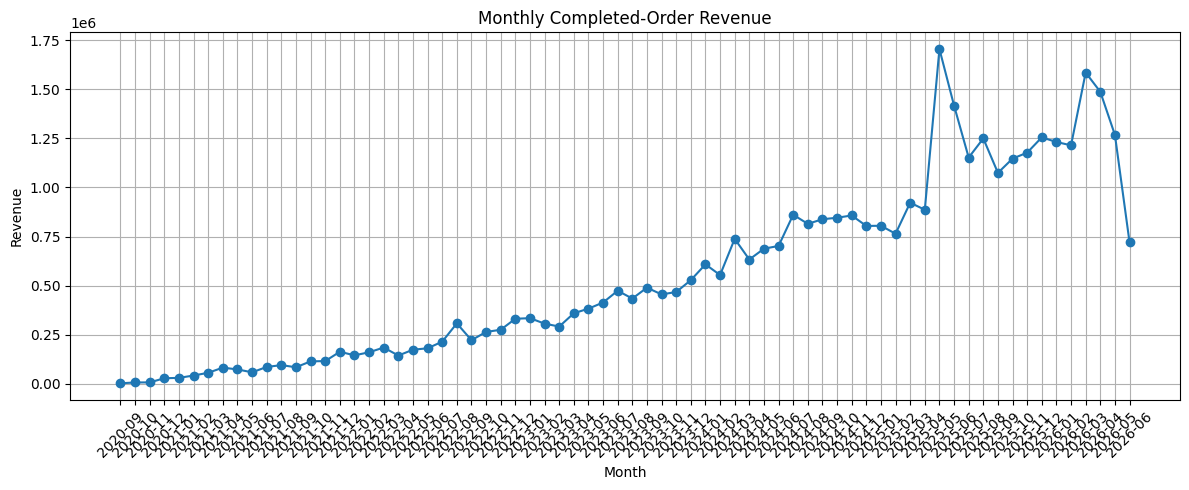

In [58]:
import matplotlib.pyplot as plt

# Exclude July because it is an incomplete month
complete_months = monthly_sales[
    monthly_sales["sales_month"] <= "2026-06"
]

plt.figure(figsize=(12, 5))

plt.plot(
    complete_months["sales_month"],
    complete_months["monthly_revenue"],
    marker="o"
)

plt.title("Monthly Completed-Order Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**Chart Interpretation**

The chart shows a downward trend in monthly completed-order revenue from March to June 2026. Revenue declined by approximately 54.5% during this period, alongside a reduction in completed orders. This suggests that the sales decline was largely associated with fewer completed transactions rather than a major reduction in average order value. July was excluded because the available data covers only part of the month.

### SQL Analysis 9 — Sales Performance by Payment Method

This query examines completed orders by payment method. It compares the number of transactions, total revenue and average order value to identify the payment methods contributing most to sales.

In [59]:
query = """
SELECT
    payment_method,
    COUNT(*) AS completed_orders,
    ROUND(SUM(total_amount), 2) AS total_revenue,
    ROUND(AVG(total_amount), 2) AS average_order_value
FROM orders
WHERE order_status = 'COMPLETED'
GROUP BY payment_method
ORDER BY total_revenue DESC;
"""

payment_analysis = pd.read_sql_query(query, conn)

payment_analysis

,payment_method,completed_orders,total_revenue,average_order_value
0,Gift Card,5220,8056440.71,1543.38
1,PayPal,5154,8004246.81,1553.02
2,Credit Card,5072,7849676.90,1547.65
3,Debit Card,5061,7704662.68,1522.36
4,Store Credit,4974,7639030.76,1535.79


### SQL Analysis 10 — Top 10 Products by Revenue

This query joins the products, order items and orders tables to identify the ten products generating the highest revenue from completed orders.

In [60]:
query = """
SELECT
    p.product_id,
    p.product_name,
    p.category,
    SUM(oi.quantity) AS units_sold,
    ROUND(SUM(oi.quantity * oi.unit_price_at_purchase), 2) AS product_revenue
FROM products AS p
INNER JOIN order_items AS oi
    ON p.product_id = oi.product_id
INNER JOIN orders AS o
    ON oi.order_id = o.order_id
WHERE o.order_status = 'COMPLETED'
  AND oi.quantity > 0
  AND oi.unit_price_at_purchase IS NOT NULL
GROUP BY
    p.product_id,
    p.product_name,
    p.category
ORDER BY product_revenue DESC
LIMIT 10;
"""

product_analysis = pd.read_sql_query(query, conn)

product_analysis

,product_id,product_name,category,units_sold,product_revenue
0,PROD1026,Sabre Fragrance X,Beauty & Personal Care,460,444603.70
1,PROD1183,BrightPath Cameras Plus,Electronics,442,440446.97
2,PROD1120,Northfield Cycling,Sports & Outdoors,439,439675.43
3,PROD1017,Nova Skincare Lite,Beauty & Personal Care,462,437829.05
4,PROD1162,Crestline Smart Home Pro,Electronics,479,429624.24
5,PROD1124,Crestline Smart Home Essential,Electronics,435,422204.64
6,PROD1091,Lumen Smartphones Pro,Electronics,445,420182.33
7,PROD1025,Vertex Wellnes,Beauty & Personal Care,449,417990.05
8,PROD1136,Everwood Wellnes Lite,Beauty & Personal Care,459,415215.88
9,PROD1114,Vertex Tablet Max,Electronics,501,392059.32


### SQL Analysis 11 — Customer Support Issues

This query examines the number of support tickets received under each issue category and calculates the average customer satisfaction score. It helps identify common customer complaints and areas requiring service improvement.

In [61]:
query = """
SELECT
    issue_category,
    COUNT(*) AS number_of_tickets,
    ROUND(AVG(satisfaction_score), 2) AS average_satisfaction
FROM support_tickets
GROUP BY issue_category
ORDER BY number_of_tickets DESC;
"""

support_analysis = pd.read_sql_query(query, conn)

support_analysis

,issue_category,number_of_tickets,average_satisfaction
0,Product Question,715,3.94
1,Refund Status,671,3.93
2,Damaged Item,663,3.87
3,Account Access,661,3.85
4,Return Request,641,3.88
5,Billing Issue,633,3.84
6,Delivery Delay,615,3.90
7,Wrong Item Shipped,601,3.93


### SQL Analysis 12 — Customer Support Experience and Purchase Activity

This query compares customer support activity and satisfaction between customers who have completed purchases and those who have not. It helps explore whether customer support experiences are associated with purchasing activity.

In [62]:
query = """
WITH customer_activity AS (
    SELECT
        customer_id,
        CASE
            WHEN SUM(
                CASE WHEN order_status = 'COMPLETED' THEN 1 ELSE 0 END
            ) > 0
            THEN 'Has Completed Purchases'
            ELSE 'No Completed Purchases'
        END AS purchase_status
    FROM orders
    GROUP BY customer_id
)
SELECT
    ca.purchase_status,
    COUNT(st.ticket_id) AS support_tickets,
    COUNT(DISTINCT st.customer_id) AS customers_with_tickets,
    ROUND(AVG(st.satisfaction_score), 2) AS average_satisfaction,
    ROUND(AVG(st.resolution_time_hours), 2) AS average_resolution_hours
FROM customer_activity AS ca
LEFT JOIN support_tickets AS st
    ON ca.customer_id = st.customer_id
GROUP BY ca.purchase_status;
"""

support_purchase_analysis = pd.read_sql_query(query, conn)

support_purchase_analysis

,purchase_status,support_tickets,customers_with_tickets,average_satisfaction,average_resolution_hours
0,Has Completed Purchases,4818,3270,3.89,18.33
1,No Completed Purchases,9,7,3.67,17.20


### Database Indexing and Performance

Database indexes can improve query performance by reducing the amount of data SQLite needs to scan when searching or joining tables. In this project, indexes will be considered for frequently used customer and transaction identifiers.

In [66]:
# Check existing indexes in the database
cursor.execute("""
    SELECT name, tbl_name
    FROM sqlite_master
    WHERE type = 'index'
    ORDER BY tbl_name;
""")

for index in cursor.fetchall():
    print(index)

In [67]:
print("Database connection:", conn)
print("Cursor:", cursor)

Database connection: <sqlite3.Connection object at 0x7c9b9edf2110>
Cursor: <sqlite3.Cursor object at 0x7c9b9ee440c0>


In [68]:
# Create indexes on frequently used join columns

cursor.execute("""
    CREATE INDEX IF NOT EXISTS idx_orders_customer_id
    ON orders(customer_id);
""")

cursor.execute("""
    CREATE INDEX IF NOT EXISTS idx_order_items_order_id
    ON order_items(order_id);
""")

cursor.execute("""
    CREATE INDEX IF NOT EXISTS idx_order_items_product_id
    ON order_items(product_id);
""")

cursor.execute("""
    CREATE INDEX IF NOT EXISTS idx_support_tickets_customer_id
    ON support_tickets(customer_id);
""")

conn.commit()

print("Database indexes created successfully.")

Database indexes created successfully.


In [69]:
cursor.execute("""
    SELECT name, tbl_name
    FROM sqlite_master
    WHERE type = 'index'
      AND name NOT LIKE 'sqlite_autoindex%'
    ORDER BY tbl_name;
""")

index_results = cursor.fetchall()

for index in index_results:
    print(f"Index: {index[0]} | Table: {index[1]}")

Index: idx_order_items_order_id | Table: order_items
Index: idx_order_items_product_id | Table: order_items
Index: idx_orders_customer_id | Table: orders
Index: idx_support_tickets_customer_id | Table: support_tickets


In [70]:
query = """
SELECT
    customer_id,
    COUNT(*) AS total_orders
FROM orders
WHERE customer_id = 'CUST002565'
GROUP BY customer_id;
"""

cursor.execute("EXPLAIN QUERY PLAN " + query)

for row in cursor.fetchall():
    print(row)

(6, 0, 0, 'SEARCH orders USING COVERING INDEX idx_orders_customer_id (customer_id=?)')


SEARCH orders USING COVERING INDEX
idx_orders_customer_id (customer_id=?)

In [71]:
cursor.execute("""
EXPLAIN QUERY PLAN
SELECT
    customer_id,
    COUNT(*) AS total_orders
FROM orders NOT INDEXED
WHERE customer_id = 'CUST002565'
GROUP BY customer_id;
""")

for row in cursor.fetchall():
    print(row)

(6, 0, 0, 'SCAN orders')


### Index Performance Evaluation

Four indexes were created on frequently used join columns: `orders.customer_id`, `order_items.order_id`, `order_items.product_id`, and `support_tickets.customer_id`.

The SQLite query execution plan was examined using `EXPLAIN QUERY PLAN`. With indexing enabled, SQLite used the `idx_orders_customer_id` covering index to search for a specific customer's orders. When the index was bypassed using `NOT INDEXED`, SQLite performed a full table scan instead.

This comparison demonstrates how indexes can help reduce unnecessary table scanning and improve data retrieval efficiency. However, actual execution-time improvements were not measured, so no specific speed increase is claimed.

## Phase 5 — Churn analysis

For the descriptive snapshot, a customer is churned if they have never made a completed purchase or have not made one in the 180 days before 1 July 2026.

# Phase 5 — Churn Analysis

This phase examines customer purchasing behaviour to identify customers who have stopped purchasing from Meridian Retail Group. It explores the overall churn rate, customer characteristics, purchasing patterns and customer support experiences to identify possible factors associated with customer churn.

## 5.1 — Definition of Customer Churn

For this analysis, the customer churn status is determined using 1 July 2026 as the snapshot date and a 180-day inactivity period.

A customer is classified as:

- **Active:** Has made at least one completed purchase within the 180 days before 1 July 2026.
- **Churned:** Has never made a completed purchase or has not made a completed purchase within the 180 days before 1 July 2026.

This definition provides a consistent basis for measuring customer churn and comparing purchasing behaviour across different customer groups.

In [ ]:
SNAPSHOT_DATE = pd.Timestamp("2026-07-01")
completed = orders[
    orders["order_status"].astype("string").str.upper().eq("COMPLETED")
    & orders["order_date"].notna()
].copy()

rfm = completed.groupby("customer_id").agg(
    last_purchase_date=("order_date","max"),
    frequency=("order_id","nunique"),
    monetary=("total_amount","sum")
).reset_index()
rfm["recency_days"] = (SNAPSHOT_DATE - rfm["last_purchase_date"]).dt.days
customer_analysis = customers.merge(rfm, on="customer_id", how="left")
customer_analysis["frequency"] = customer_analysis["frequency"].fillna(0)
customer_analysis["monetary"] = customer_analysis["monetary"].fillna(0)
customer_analysis["churned"] = (
    customer_analysis["last_purchase_date"].isna()
    | (customer_analysis["recency_days"] > 180)
).astype(int)
customer_analysis["churn_status"] = customer_analysis["churned"].map({1:"Churned",0:"Active"})
display(customer_analysis["churn_status"].value_counts())
print("Churn rate:", round(customer_analysis["churned"].mean()*100, 2), "%")

for col in ["membership_tier","preferred_channel","state","referral_source"]:
    if col in customer_analysis:
        display(customer_analysis.groupby(col, dropna=False).agg(
            customers=("customer_id","nunique"), churn_rate=("churned","mean")
        ).sort_values("churn_rate", ascending=False))


## 5.2 — Overall Customer Churn Distribution

This section examines the overall customer churn situation as of 1 July 2026. Customers are classified based on their completed purchase activity during the preceding 180 days. Customers who have never made a completed purchase are also classified as churned.

In [72]:
import pandas as pd

# Define the snapshot date and inactivity period
snapshot_date = pd.Timestamp("2026-07-01")
churn_cutoff = snapshot_date - pd.Timedelta(days=180)

# Get each customer's most recent completed purchase
completed_orders = orders_clean[
    orders_clean["order_status"] == "COMPLETED"
].copy()

last_purchase = (
    completed_orders.groupby("customer_id")["order_date"]
    .max()
    .reset_index()
    .rename(columns={"order_date": "last_purchase_date"})
)

# Include every registered customer
churn_analysis = customers_clean[["customer_id"]].merge(
    last_purchase,
    on="customer_id",
    how="left"
)

# Classify customers
churn_analysis["customer_status"] = "Churned"

churn_analysis.loc[
    churn_analysis["last_purchase_date"] >= churn_cutoff,
    "customer_status"
] = "Active"

# Summarise the results
churn_summary = (
    churn_analysis["customer_status"]
    .value_counts()
    .reindex(["Active", "Churned"], fill_value=0)
    .reset_index()
)

churn_summary.columns = ["Customer Status", "Number of Customers"]

churn_summary["Percentage"] = (
    churn_summary["Number of Customers"]
    / len(churn_analysis) * 100
).round(2)

churn_summary

,Customer Status,Number of Customers,Percentage
0,Active,2018,33.14
1,Churned,4072,66.86


### Interpretation of Overall Customer Churn

The analysis shows that Meridian Retail Group has 6,090 registered customers, of which 2,018 (33.14%) are active and 4,072 (66.86%) are classified as churned.

This indicates a high level of customer inactivity, with approximately two-thirds of the registered customer base classified as churned under the 180-day inactivity definition.

The result highlights a potential customer-retention challenge. Further analysis is required to distinguish customers who have never made a completed purchase from previous buyers who have become inactive and to identify customer characteristics associated with churn.

### 5.3.1 — Customer Churn by Membership Tier

This analysis examines customer churn across the four membership tiers: Bronze, Silver, Gold and Platinum. The objective is to identify whether customer inactivity differs across membership levels and determine which tier has the highest churn rate.

In [73]:
# Combine customer membership information with churn status
tier_analysis = customers_clean[
    ["customer_id", "membership_tier"]
].merge(
    churn_analysis[["customer_id", "customer_status"]],
    on="customer_id",
    how="left"
)

# Calculate customer totals and churned customers per tier
tier_summary = (
    tier_analysis.groupby("membership_tier", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=(
            "customer_status",
            lambda x: (x == "Churned").sum()
        )
    )
    .reset_index()
)

# Calculate churn rate
tier_summary["churn_rate"] = (
    tier_summary["churned_customers"]
    / tier_summary["total_customers"] * 100
).round(2)

tier_summary.sort_values(
    "churn_rate", ascending=False
)

,membership_tier,total_customers,churned_customers,churn_rate
1,Gold,1126,765,67.94
3,Silver,1768,1184,66.97
0,Bronze,2785,1851,66.46
2,Platinum,411,272,66.18


#### Interpretation of Customer Churn by Membership Tier

The analysis shows that Gold members recorded the highest churn rate at 67.94%, followed by Silver at 66.97%, Bronze at 66.46% and Platinum at 66.18%.

The difference between the highest and lowest churn rates is relatively small, indicating that customer inactivity affects all membership tiers. This suggests that membership level alone may not be sufficient to explain customer churn.

Meridian Retail Group should investigate other factors, including pricing, product satisfaction, purchasing behaviour and customer experience, when developing customer-retention strategies.

In [74]:
channel_analysis = customers_clean[
    ["customer_id", "preferred_channel"]
].merge(
    churn_analysis[["customer_id", "customer_status"]],
    on="customer_id",
    how="left"
)

channel_summary = (
    channel_analysis.groupby("preferred_channel", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=(
            "customer_status",
            lambda x: (x == "Churned").sum()
        )
    )
    .reset_index()
)

channel_summary["churn_rate"] = (
    channel_summary["churned_customers"]
    / channel_summary["total_customers"] * 100
).round(2)

channel_summary.sort_values(
    "churn_rate", ascending=False
)

,preferred_channel,total_customers,churned_customers,churn_rate
0,In-Store,2041,1387,67.96
1,Mobile App,2053,1368,66.63
2,Online,1996,1317,65.98


#### Interpretation of Customer Churn by Preferred Shopping Channel

The analysis shows that In-Store customers recorded the highest churn rate at 67.96%, followed by Mobile App customers at 66.63% and Online customers at 65.98%.

Although In-Store customers have the highest churn rate, the difference between the highest and lowest rates is relatively small at 1.98 percentage points. This indicates that customer inactivity affects all three shopping channels.

The findings suggest that preferred shopping channel alone may not adequately explain customer churn. Further investigation into pricing, product availability, shopping experience and customer satisfaction may provide additional insights.

#### 5.3.3 — Customer Churn by State

This analysis examines customer churn across geographical locations to identify states with relatively high or low customer inactivity. It will help determine whether customer retention differs across the company's geographical markets.

In [75]:
state_analysis = customers_clean[
    ["customer_id", "state"]
].merge(
    churn_analysis[["customer_id", "customer_status"]],
    on="customer_id",
    how="left"
)

state_summary = (
    state_analysis.groupby("state", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=(
            "customer_status",
            lambda x: (x == "Churned").sum()
        )
    )
    .reset_index()
)

state_summary["churn_rate"] = (
    state_summary["churned_customers"]
    / state_summary["total_customers"] * 100
).round(2)

state_summary.sort_values(
    "churn_rate", ascending=False
).head(15)

,state,total_customers,churned_customers,churn_rate
73,oh,25,22,88.00
46,TEXAS,30,25,83.33
71,nj,34,27,79.41
76,tx,24,19,79.17
10,GEORGIA,33,26,78.79
57,WISCONSIN,36,28,77.78
75,tn,36,28,77.78
4,CALIFORNIA,30,23,76.67
77,va,38,29,76.32
52,VIRGINIA,38,29,76.32


#### Initial Observation of Customer Churn by State

The initial geographical analysis shows relatively high churn rates across several state labels. However, the results reveal inconsistencies in state naming, including the use of abbreviations, lowercase entries and full state names.

For example, Texas appears as both `TEXAS` and `tx`, while Michigan appears as `MI` and `MICHIGAN`. These inconsistencies may divide customers from the same geographical location into separate groups.

Therefore, the state values must be standardised before drawing final conclusions about geographical customer churn. The initial results are treated as preliminary observations.

# Display all unique state names in the customer dataset
state_values = sorted(
    customers_clean["state"]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
)

print("Number of unique state labels:", len(state_values))

for state in state_values:
    print(state)

In [76]:
# Inspect all unique state names
state_values = sorted(
    customers_clean["state"]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
)

print("Number of unique state labels:", len(state_values))

print(state_values)

Number of unique state labels: 80
['ARIZONA', 'AZ', 'Arizona', 'CA', 'CALIFORNIA', 'California', 'FL', 'FLORIDA', 'Florida', 'GA', 'GEORGIA', 'Georgia', 'IL', 'ILLINOIS', 'IN', 'INDIANA', 'Illinois', 'Indiana', 'MA', 'MARYLAND', 'MASSACHUSETTS', 'MD', 'MI', 'MICHIGAN', 'MISSOURI', 'MO', 'Maryland', 'Massachusetts', 'Michigan', 'Missouri', 'NC', 'NEW JERSEY', 'NEW YORK', 'NJ', 'NORTH CAROLINA', 'NY', 'New Jersey', 'New York', 'North Carolina', 'OH', 'OHIO', 'Ohio', 'PA', 'PENNSYLVANIA', 'Pennsylvania', 'TENNESSEE', 'TEXAS', 'TN', 'TX', 'Tennessee', 'Texas', 'VA', 'VIRGINIA', 'Virginia', 'WA', 'WASHINGTON', 'WI', 'WISCONSIN', 'Washington', 'Wisconsin', 'az', 'ca', 'fl', 'ga', 'il', 'in', 'ma', 'md', 'mi', 'mo', 'nc', 'nj', 'ny', 'oh', 'pa', 'tn', 'tx', 'va', 'wa', 'wi']


In [77]:
# Create a mapping for state abbreviations and full names
state_mapping = {
    "AZ": "Arizona",
    "CA": "California",
    "FL": "Florida",
    "GA": "Georgia",
    "IL": "Illinois",
    "IN": "Indiana",
    "MA": "Massachusetts",
    "MD": "Maryland",
    "MI": "Michigan",
    "MO": "Missouri",
    "NC": "North Carolina",
    "NJ": "New Jersey",
    "NY": "New York",
    "OH": "Ohio",
    "PA": "Pennsylvania",
    "TN": "Tennessee",
    "TX": "Texas",
    "VA": "Virginia",
    "WA": "Washington",
    "WI": "Wisconsin"
}

# Create a standardised state column
state_analysis["state_standardized"] = (
    state_analysis["state"]
    .str.strip()
    .str.upper()
    .map(state_mapping)
)

print("State standardisation completed.")

print(
    "Number of unique standardised states:",
    state_analysis["state_standardized"].nunique()
)

State standardisation completed.
Number of unique standardised states: 20


State standardisation completed.
Number of unique standardised states: 20

In [78]:
# Calculate churn by standardised state
state_summary_clean = (
    state_analysis.groupby("state_standardized", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=(
            "customer_status",
            lambda x: (x == "Churned").sum()
        )
    )
    .reset_index()
)

# Calculate churn rate
state_summary_clean["churn_rate"] = (
    state_summary_clean["churned_customers"]
    / state_summary_clean["total_customers"] * 100
).round(2)

# Display the 20 states, ranked by churn rate
state_summary_clean.sort_values(
    "churn_rate", ascending=False
)

,state_standardized,total_customers,churned_customers,churn_rate
19,Wisconsin,138,101,73.19
8,Michigan,149,109,73.15
15,Tennessee,144,104,72.22
10,New Jersey,146,105,71.92
13,Ohio,164,117,71.34
0,Arizona,165,116,70.30
2,Florida,151,106,70.20
17,Virginia,156,108,69.23
16,Texas,162,112,69.14
4,Illinois,151,102,67.55


#### Interpretation of Customer Churn by State

After standardising the state names, the analysis revealed differences in customer churn across the 20 identified states. Wisconsin recorded the highest churn rate at 73.19%, closely followed by Michigan at 73.15%. Washington recorded the lowest churn rate at 58.62%.

The difference between the highest and lowest state churn rates was 14.57 percentage points, suggesting that customer inactivity varies across geographical locations.

However, 3,080 customers had missing state information, representing a substantial portion of the customer database. These customers were retained in the overall churn analysis but should be excluded from geographical comparisons because their locations could not be established.

The results suggest that Meridian Retail Group should investigate geographical differences in customer purchasing behaviour and consider targeted retention strategies in states with relatively high churn rates. However, these differences do not establish the reasons for churn.

#### 5.3.4 — Customer Churn by Referral Source

This analysis examines customer churn across different referral sources. The objective is to determine whether customer retention differs according to how customers were initially introduced to Meridian Retail Group.

In [79]:
referral_analysis = customers_clean[
    ["customer_id", "referral_source"]
].merge(
    churn_analysis[["customer_id", "customer_status"]],
    on="customer_id",
    how="left"
)

referral_summary = (
    referral_analysis.groupby("referral_source", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=(
            "customer_status",
            lambda x: (x == "Churned").sum()
        )
    )
    .reset_index()
)

referral_summary["churn_rate"] = (
    referral_summary["churned_customers"]
    / referral_summary["total_customers"] * 100
).round(2)

referral_summary.sort_values(
    "churn_rate", ascending=False
)

,referral_source,total_customers,churned_customers,churn_rate
1,Friend Referral,614,422,68.73
7,<NA>,1705,1166,68.39
4,Social Media,650,444,68.31
5,TV Ad,635,425,66.93
6,Walk-in,649,429,66.10
3,Search Engine,604,395,65.40
0,Email Campaign,604,394,65.23
2,Influencer,629,397,63.12


#### 5.3.5 — Customer Churn by Signup Period

This analysis examines customer churn according to the period customers registered with Meridian Retail Group. Customers will be grouped by signup year to identify differences in retention across customer acquisition cohorts.

In [80]:
# Combine signup dates with customer churn status
cohort_analysis = customers_clean[
    ["customer_id", "signup_date"]
].merge(
    churn_analysis[["customer_id", "customer_status"]],
    on="customer_id",
    how="left"
)

# Extract signup year
cohort_analysis["signup_year"] = (
    cohort_analysis["signup_date"].dt.year
)

# Calculate churn by signup year
cohort_summary = (
    cohort_analysis.groupby("signup_year", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=(
            "customer_status",
            lambda x: (x == "Churned").sum()
        )
    )
    .reset_index()
)

# Calculate churn rate
cohort_summary["churn_rate"] = (
    cohort_summary["churned_customers"]
    / cohort_summary["total_customers"] * 100
).round(2)

cohort_summary.sort_values("signup_year")

,signup_year,total_customers,churned_customers,churn_rate
0,2020.0,274,231,84.31
1,2021.0,986,827,83.87
2,2022.0,947,769,81.20
3,2023.0,973,760,78.11
4,2024.0,945,642,67.94
5,2025.0,999,512,51.25
6,2026.0,479,46,9.60
7,NaN,487,285,58.52


The analysis shows that customers who registered in earlier years generally recorded higher churn rates than those who registered more recently. The 2020 cohort had the highest churn rate at 84.31%, closely followed by the 2021 cohort at 83.87%. In comparison, the 2025 cohort recorded a churn rate of 51.25%, while the 2026 cohort had the lowest rate at 9.60%.

This pattern suggests that customer inactivity varies across signup periods. However, the lower churn rates among recent customers should be interpreted cautiously because they have had less time to reach the 180-day inactivity threshold. In addition, 487 customers had missing signup dates, of whom 285 were classified as churned. These customers were retained in the overall churn analysis but could not be assigned to a specific signup cohort.

Meridian Retail Group should investigate the experiences and purchasing patterns of long-standing customers to understand why many have become inactive. The business should also continue monitoring recent customer cohorts to determine whether their apparently lower churn rates are sustained over time.

This section uses Recency, Frequency and Monetary (RFM) analysis to examine customer purchasing behaviour and identify differences between active and churned customers.

Recency measures the number of days since a customer's most recent completed purchase. Frequency measures the number of completed orders placed by each customer, while Monetary measures the total amount spent on completed orders.

The analysis uses 1 July 2026 as the reference date and focuses on completed purchases to provide a consistent view of customer activity and spending.

In [81]:
# Calculate the last completed purchase for each customer
rfm_last_purchase = (
    completed_orders.groupby("customer_id")["order_date"]
    .max()
    .reset_index()
    .rename(columns={"order_date": "last_purchase_date"})
)

# Calculate purchase frequency and total spending
rfm_purchase_summary = (
    completed_orders.groupby("customer_id")
    .agg(
        frequency=("order_id", "nunique"),
        monetary=("total_amount", "sum")
    )
    .reset_index()
)

# Combine the RFM information with all registered customers
rfm_analysis = (
    customers_clean[["customer_id"]]
    .merge(rfm_last_purchase, on="customer_id", how="left")
    .merge(rfm_purchase_summary, on="customer_id", how="left")
)

# Calculate recency in days
rfm_analysis["recency"] = (
    snapshot_date - rfm_analysis["last_purchase_date"]
).dt.days

# Customers without completed purchases receive zero frequency and spending
rfm_analysis[["frequency", "monetary"]] = (
    rfm_analysis[["frequency", "monetary"]].fillna(0)
)

# Attach customer churn status
rfm_analysis = rfm_analysis.merge(
    churn_analysis[["customer_id", "customer_status"]],
    on="customer_id",
    how="left"
)

rfm_analysis.head()

,customer_id,last_purchase_date,frequency,monetary,recency,customer_status
0,CUST002565,2026-06-01,7.0,9149.70,30.0,Active
1,CUST004275,NaT,0.0,0.00,NaN,Churned
2,CUST003045,2024-09-05,3.0,8742.62,664.0,Churned
3,CUST005168,2025-12-27,4.0,9395.18,186.0,Churned
4,CUST003986,2024-09-21,4.0,4670.25,648.0,Churned


This analysis compares the average Recency, Frequency and Monetary values of active and churned customers. The comparison will help identify differences in purchasing activity, purchase frequency and customer spending between the two groups.

In [82]:
# Compare RFM measures by customer status
rfm_summary = (
    rfm_analysis.groupby("customer_status")
    .agg(
        average_recency=("recency", "mean"),
        average_frequency=("frequency", "mean"),
        average_monetary=("monetary", "mean")
    )
    .round(2)
    .reset_index()
)

rfm_summary

,customer_status,average_recency,average_frequency,average_monetary
0,Active,89.19,4.87,7540.46
1,Churned,515.71,3.84,5896.74


The RFM analysis reveals noticeable differences in the purchasing behaviour of active and churned customers. Active customers recorded an average recency of 89.19 days, compared with 515.71 days for churned customers, indicating that churned customers have been inactive for considerably longer.

Active customers also recorded a higher average purchase frequency of 4.87 orders, compared with 3.84 orders among churned customers. Similarly, their average monetary value was 7,540.46, compared with 5,896.74 for churned customers.

These findings suggest that active customers tend to purchase more recently, more frequently and spend more than churned customers. Recency appears particularly useful for distinguishing the two groups. Meridian Retail Group should consider monitoring customer purchase intervals and identifying customers whose purchasing activity has declined as part of its retention strategy.

To obtain a clearer understanding of customer purchasing behaviour, this analysis focuses on customers who have made at least one completed purchase. Customers with no completed purchase history are excluded because their frequency and monetary values are zero and their recency values are unavailable. This allows a more meaningful comparison between active customers and previously purchasing customers who have become inactive.

In [83]:
# Retain only customers with at least one completed purchase
rfm_previous_buyers = rfm_analysis[
    rfm_analysis["last_purchase_date"].notna()
].copy()

# Compare RFM measures by customer status
rfm_previous_buyers_summary = (
    rfm_previous_buyers.groupby("customer_status")
    .agg(
        total_customers=("customer_id", "nunique"),
        average_recency=("recency", "mean"),
        average_frequency=("frequency", "mean"),
        average_monetary=("monetary", "mean")
    )
    .round(2)
    .reset_index()
)

rfm_previous_buyers_summary

,customer_status,total_customers,average_recency,average_frequency,average_monetary
0,Active,2018,89.19,4.87,7540.46
1,Churned,3625,515.71,4.31,6620.82


After excluding customers who had never made a completed purchase, the analysis identified 3,625 churned previous buyers and 2,018 active customers. The results show that active customers recorded an average recency of 89.19 days, compared with 515.71 days among churned previous buyers. Active customers also had a higher average purchase frequency of 4.87 orders and average monetary value of 7,540.46, compared with 4.31 orders and 6,620.82 respectively among churned previous buyers.

An important observation is that churned previous buyers had made an average of 4.31 completed purchases before becoming inactive. This suggests that a considerable number of customers who became inactive had previously established purchasing relationships with the business. Meridian Retail Group should therefore investigate why previously engaged customers stopped purchasing and consider targeted reactivation campaigns for this group.

This analysis examines support-ticket activity among active and churned customers to identify possible differences in their customer-service experiences.

In [84]:
# Count support tickets submitted by each customer
ticket_counts = (
    support_tickets_clean.groupby("customer_id")
    .size()
    .reset_index(name="ticket_count")
)

# Combine ticket counts with customer churn status
customer_support = churn_analysis[
    ["customer_id", "customer_status"]
].merge(
    ticket_counts,
    on="customer_id",
    how="left"
)

# Customers without tickets receive a zero count
customer_support["ticket_count"] = (
    customer_support["ticket_count"].fillna(0)
)

# Compare support-ticket activity by customer status
support_churn_summary = (
    customer_support.groupby("customer_status")
    .agg(
        total_customers=("customer_id", "nunique"),
        customers_with_tickets=(
            "ticket_count",
            lambda x: (x > 0).sum()
        ),
        total_tickets=("ticket_count", "sum"),
        average_tickets_per_customer=("ticket_count", "mean")
    )
    .round(2)
    .reset_index()
)

support_churn_summary

,customer_status,total_customers,customers_with_tickets,total_tickets,average_tickets_per_customer
0,Active,2018,1163,1665.0,0.83
1,Churned,4072,2366,3535.0,0.87


The analysis shows that 1,163 active customers and 2,366 churned customers had submitted support tickets. Churned customers recorded a slightly higher average of 0.87 tickets per customer compared with 0.83 among active customers. Although this indicates a small difference in support-ticket activity, ticket frequency alone does not establish the cause of customer churn. Further consideration of customer satisfaction and ticket resolution time is necessary to understand possible service-related issues.

This analysis compares customer satisfaction scores and support-ticket resolution times between active and churned customers to identify possible differences in their support experiences.


In [86]:
support_tickets_clean.columns.tolist()

['ticket_id',
 'customer_id',
 'ticket_date',
 'issue_category',
 'channel',
 'resolution_time_hours',
 'satisfaction_score',
 'ticket_text']

In [87]:
# Attach churn status to support tickets
ticket_analysis = support_tickets_clean.merge(
    churn_analysis[["customer_id", "customer_status"]],
    on="customer_id",
    how="inner"
)

# Compare satisfaction and resolution time
ticket_experience_summary = (
    ticket_analysis.groupby("customer_status")
    .agg(
        total_tickets=("ticket_id", "count"),
        average_satisfaction=("satisfaction_score", "mean"),
        average_resolution_time=("resolution_time_hours", "mean")
    )
    .round(2)
    .reset_index()
)

ticket_experience_summary

,customer_status,total_tickets,average_satisfaction,average_resolution_time
0,Active,1665,3.89,17.74
1,Churned,3535,3.89,18.83


The analysis shows that active and churned customers recorded the same average customer satisfaction score of 3.89. However, the average support-ticket resolution time was slightly higher among churned customers at 18.83 hours, compared with 17.74 hours for active customers. Although this difference may indicate a variation in customer-service experience, the results do not establish a direct relationship between support-ticket resolution time and customer churn. Further investigation may be required to understand whether service experiences contribute to customer inactivity.

## Phase 6 — Visualisation

Each chart is followed by a short note describing the comparison it presents.

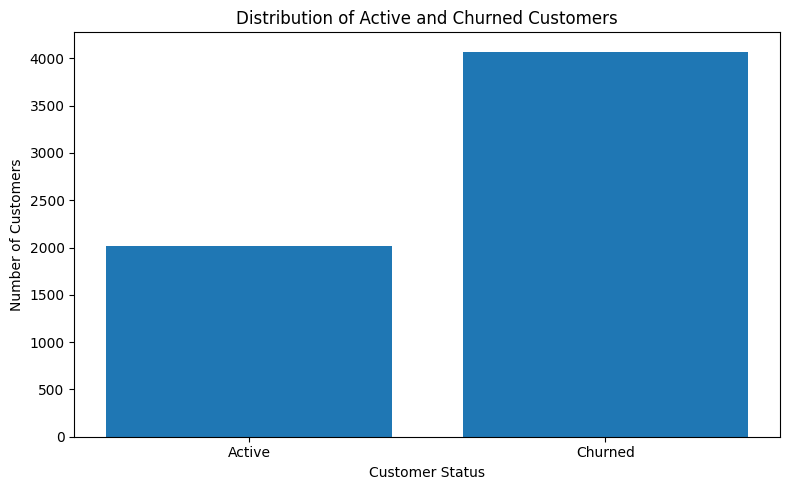

In [88]:
import matplotlib.pyplot as plt

# Prepare data
statuses = churn_summary["Customer Status"]
customer_counts = churn_summary["Number of Customers"]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(statuses, customer_counts)

plt.title("Distribution of Active and Churned Customers")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

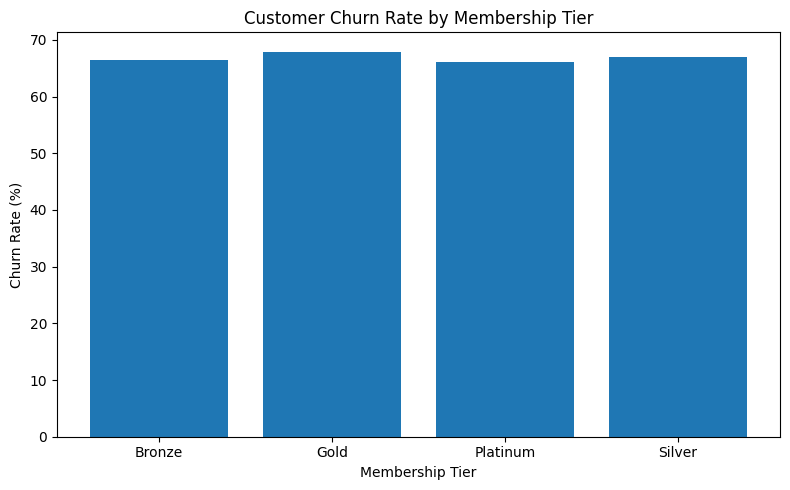

In [89]:
# Calculate churn rate by membership tier
tier_chart_data = (
    tier_analysis.groupby("membership_tier")
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=(
            "customer_status",
            lambda x: (x == "Churned").sum()
        )
    )
    .reset_index()
)

tier_chart_data["churn_rate"] = (
    tier_chart_data["churned_customers"]
    / tier_chart_data["total_customers"] * 100
)

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(
    tier_chart_data["membership_tier"],
    tier_chart_data["churn_rate"]
)

plt.title("Customer Churn Rate by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

The chart compares customer churn rates across the four membership tiers. Gold recorded the highest churn rate at 67.94%, while Platinum recorded the lowest at 66.18%. The relatively small differences suggest that churn affects customers across all membership levels.

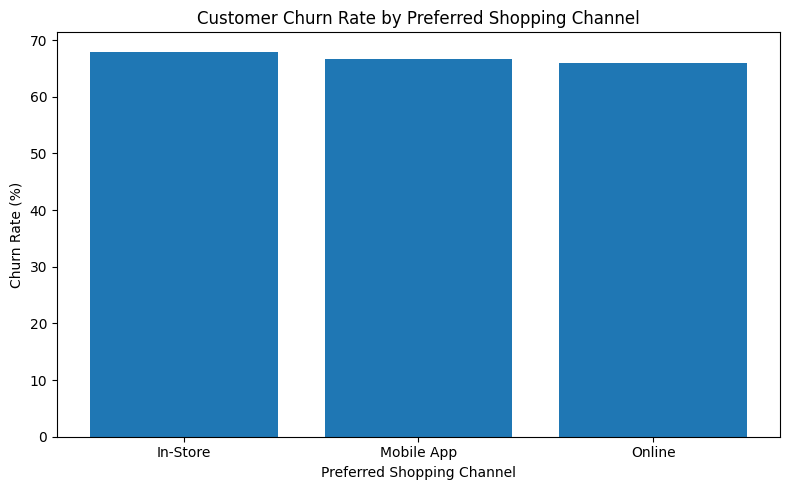

In [90]:
# Prepare churn data by preferred shopping channel
channel_chart_data = (
    customers_clean[["customer_id", "preferred_channel"]]
    .merge(
        churn_analysis[["customer_id", "customer_status"]],
        on="customer_id",
        how="left"
    )
    .groupby("preferred_channel")
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=(
            "customer_status",
            lambda x: (x == "Churned").sum()
        )
    )
    .reset_index()
)

channel_chart_data["churn_rate"] = (
    channel_chart_data["churned_customers"]
    / channel_chart_data["total_customers"] * 100
)

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(
    channel_chart_data["preferred_channel"],
    channel_chart_data["churn_rate"]
)

plt.title("Customer Churn Rate by Preferred Shopping Channel")
plt.xlabel("Preferred Shopping Channel")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

The chart compares customer churn rates across the three preferred shopping channels. In-Store customers recorded the highest churn rate at 67.96%, followed by Mobile App customers at 66.63% and Online customers at 65.98%. The small differences indicate that churn affects customers across all three channels.

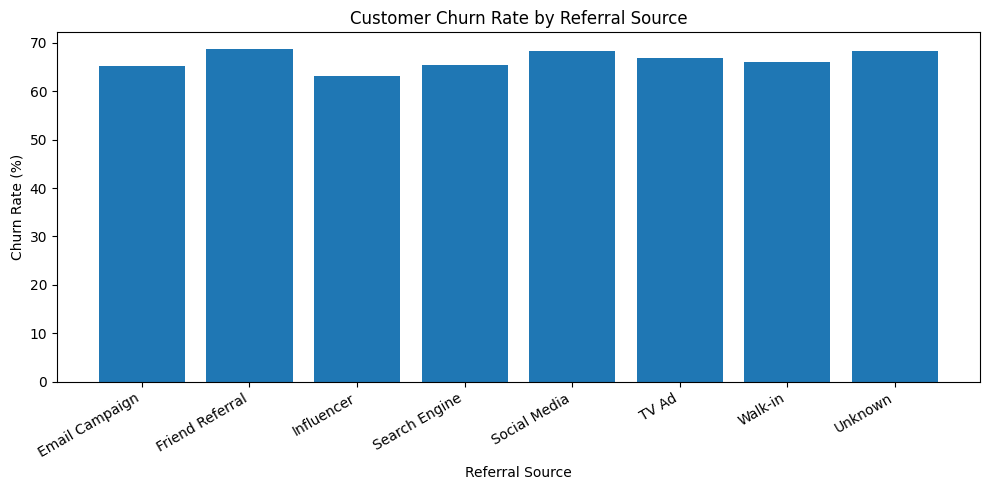

In [91]:
# Prepare churn data by referral source
referral_chart_data = (
    customers_clean[["customer_id", "referral_source"]]
    .merge(
        churn_analysis[["customer_id", "customer_status"]],
        on="customer_id",
        how="left"
    )
    .groupby("referral_source", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=(
            "customer_status",
            lambda x: (x == "Churned").sum()
        )
    )
    .reset_index()
)

referral_chart_data["churn_rate"] = (
    referral_chart_data["churned_customers"]
    / referral_chart_data["total_customers"] * 100
)

# Replace missing referral source for display
referral_chart_data["referral_source"] = (
    referral_chart_data["referral_source"]
    .fillna("Unknown")
)

# Create bar chart
plt.figure(figsize=(10, 5))
plt.bar(
    referral_chart_data["referral_source"],
    referral_chart_data["churn_rate"]
)

plt.title("Customer Churn Rate by Referral Source")
plt.xlabel("Referral Source")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

The chart compares customer churn rates across different referral sources. Friend Referral recorded the highest churn rate at 68.73%, while Influencer referrals recorded the lowest at 63.12%. The results suggest that customer retention varies across acquisition sources, although missing referral information limits the completeness of the comparison.

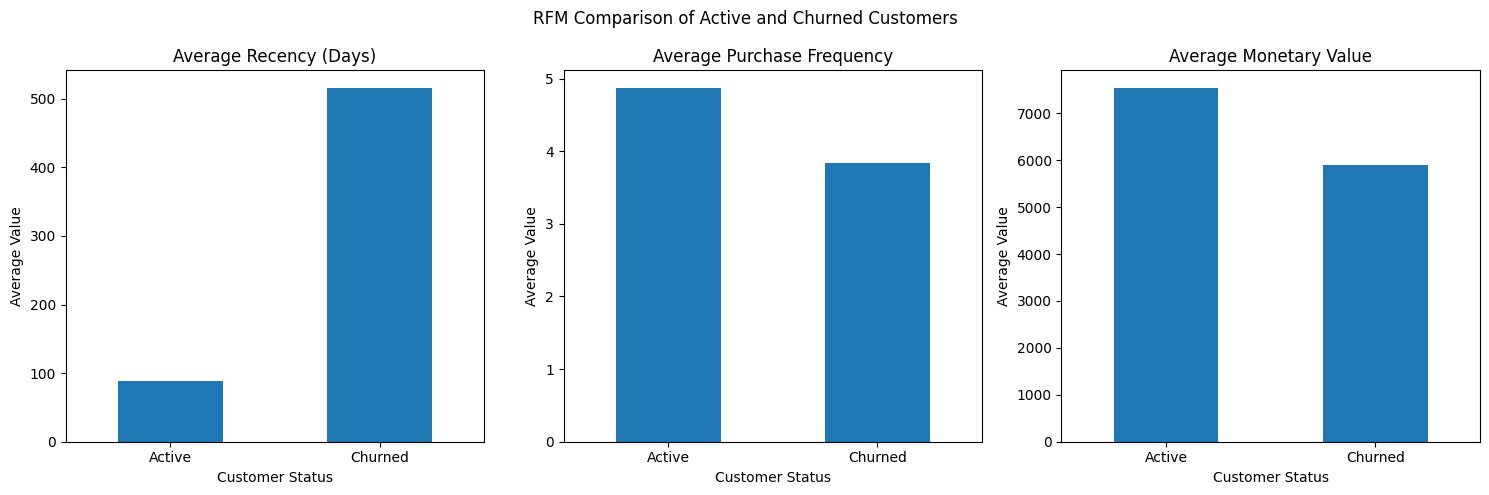

In [92]:
# Prepare RFM data for visualisation
rfm_plot_data = rfm_summary.set_index("customer_status")

# Create three side-by-side bar charts
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = [
    ("average_recency", "Average Recency (Days)"),
    ("average_frequency", "Average Purchase Frequency"),
    ("average_monetary", "Average Monetary Value")
]

for ax, (column, title) in zip(axes, metrics):
    rfm_plot_data[column].plot(
        kind="bar",
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Customer Status")
    ax.set_ylabel("Average Value")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("RFM Comparison of Active and Churned Customers")
plt.tight_layout()
plt.show()

The charts compare the purchasing behaviour of active and churned customers using Recency, Frequency and Monetary measures. Churned customers recorded a higher average recency of 515.71 days, compared with 89.19 days for active customers. Active customers also recorded higher average purchase frequency and monetary value. These differences highlight the importance of recent purchasing activity in identifying customers at risk of churn.

In [93]:
import plotly.express as px

# Select completed orders with valid dates
monthly_sales = orders_clean[
    (orders_clean["order_status"] == "COMPLETED") &
    (orders_clean["order_date"].notna())
].copy()

# Group sales by month
monthly_sales["sales_month"] = (
    monthly_sales["order_date"].dt.to_period("M").astype(str)
)

monthly_sales_summary = (
    monthly_sales.groupby("sales_month")["total_amount"]
    .sum()
    .reset_index()
    .rename(columns={"total_amount": "total_sales"})
)

# Create interactive line chart
fig = px.line(
    monthly_sales_summary,
    x="sales_month",
    y="total_sales",
    markers=True,
    title="Monthly Sales Revenue Trend",
    labels={
        "sales_month": "Month",
        "total_sales": "Total Sales Revenue"
    }
)

fig.update_layout(
    xaxis_tickangle=-45,
    hovermode="x unified"
)

fig.show()

The interactive chart illustrates monthly sales revenue from completed orders. It allows the business to examine changes in sales over time, identify stronger and weaker sales periods, and investigate possible fluctuations in customer purchasing activity.

In [94]:
# Prepare state churn data for visualisation
state_plot_data = state_summary_clean.dropna(
    subset=["state_standardized"]
).copy()

# Create interactive bar chart
fig = px.bar(
    state_plot_data.sort_values(
        "churn_rate",
        ascending=False
    ),
    x="state_standardized",
    y="churn_rate",
    hover_data=[
        "total_customers",
        "churned_customers"
    ],
    title="Interactive Customer Churn Rate by State",
    labels={
        "state_standardized": "State",
        "churn_rate": "Churn Rate (%)",
        "total_customers": "Total Customers",
        "churned_customers": "Churned Customers"
    }
)

fig.update_layout(
    xaxis_tickangle=-45,
    yaxis_title="Churn Rate (%)"
)

fig.show()

The interactive chart compares customer churn rates across the 20 identified states. Wisconsin and Michigan recorded the highest churn rates, while Washington recorded the lowest. The chart allows users to explore individual state results, including the number of registered and churned customers. Customers with missing state information were excluded from this geographical comparison.

## Phase 7 — Exploratory Data Analysis

### Key Findings from Exploratory Data Analysis

1. **High overall customer churn:** Of the 6,090 registered customers, 4,072 (66.86%) were classified as churned, while 2,018 (33.14%) remained active. This indicates a substantial customer-retention challenge for Meridian Retail Group.

2. **Churn is relatively consistent across membership tiers:** Gold customers recorded the highest churn rate at 67.94%, while Platinum customers had the lowest at 66.18%. The small difference suggests that membership tier alone may not adequately explain customer churn.

3. **The preferred sales channel shows only modest differences:** In-Store customers had the highest churn rate at 67.96%, compared with 66.63% for Mobile App customers and 65.98% for Online customers. This suggests that churn affects customers across all three channels.

4. **Acquisition source may be associated with customer retention:** Customers acquired through Friend Referral had a churn rate of 68.73%, while those acquired through Influencer campaigns had the lowest rate at 63.12%. This difference deserves further investigation, although it does not establish that the acquisition source caused the difference.

5. **Earlier signup cohorts recorded higher churn rates:** Customers who joined in 2020 and 2021 had churn rates of 84.31% and 83.87%, respectively, compared with 9.60% for the 2026 cohort. However, newer customers have had less time to meet the 180-day inactivity definition, so these figures should not be interpreted as direct evidence that newer customers are more loyal.

6. **Churned previous buyers showed weaker purchasing behaviour:** Among customers who had previously purchased, churned customers had an average recency of 515.71 days, compared with 89.19 days for active customers. They also had lower average purchase frequency (4.31 versus 4.87) and monetary value (₦6,620.82 versus ₦7,540.46). This suggests that longer periods without purchasing, together with lower spending and purchase frequency, are useful indicators of churn.

7. **Support-ticket volume alone does not clearly distinguish churned customers:** Churned customers averaged 0.87 support tickets per customer, compared with 0.83 among active customers. Average satisfaction was the same at 3.89 for both groups, while average resolution time was slightly higher for churned customers (18.83 hours versus 17.74 hours). These differences are modest and do not establish a causal relationship between support experience and churn.

8. **Geographical differences exist, but missing data limits interpretation:** Wisconsin and Michigan recorded the highest observed state churn rates, at 73.19% and 73.15%, respectively, while Washington recorded the lowest at 58.62%. However, state information was missing for approximately half of the customer records, so the geographical findings should be interpreted cautiously.

### EDA Conclusion

The analysis indicates that customer inactivity is associated with longer purchase recency and weaker purchasing behaviour. Churn also varies across acquisition sources and geographical locations, although differences across membership tiers and preferred channels are relatively small. Support-ticket measures show only modest differences between active and churned customers. These findings provide a basis for selecting behavioural and customer-related features for the predictive modelling phase.

## Phase 8 — Chart Captions

### Visualisation Captions

**Figure 1: Distribution of Active and Churned Customers**

The chart shows that churned customers account for 66.86% of the registered customer base, compared with 33.14% who remain active. This highlights the scale of Meridian Retail Group's customer-retention challenge.

**Figure 2: Customer Churn Rate by Membership Tier**

The chart compares churn rates across membership tiers. Gold customers recorded the highest churn rate (67.94%), while Platinum customers recorded the lowest (66.18%), indicating relatively small differences between tiers.

**Figure 3: Customer Churn Rate by Preferred Channel**

The visualisation compares churn rates across In-Store, Mobile App and Online customers. In-Store customers recorded the highest rate (67.96%), while Online customers recorded the lowest (65.98%).

**Figure 4: Customer Churn Rate by Referral Source**

The chart shows differences in churn rates across customer acquisition sources. Friend Referral recorded the highest rate (68.73%), while Influencer campaigns recorded the lowest (63.12%).

**Figure 5: RFM Comparison of Active and Churned Customers**

The three-panel visualisation compares recency, purchase frequency and monetary value between active and churned customers. Churned previous buyers show longer purchase inactivity and lower average purchase frequency and spending than active customers.

**Figure 6: Monthly Sales Revenue Trend — Interactive Plotly Chart**

The interactive line chart displays monthly revenue generated from completed orders. It helps identify changes in sales performance over time and periods of relatively higher or lower revenue.

**Figure 7: Interactive Customer Churn Rate by State**

The interactive bar chart compares churn rates across states. Wisconsin and Michigan recorded the highest observed rates, while Washington recorded the lowest; customers with missing state information were excluded.

## Phase 9 — Machine Learning

After running the notebook, record at least five findings supported by the tables and charts. Explain which customer behaviours are associated with churn, whether differences across segments are substantial, and what actions Meridian could test. Do not describe an association as proof of cause. State the limitations of the data, the churn definition and the model.

In [95]:
import sqlite3
import pandas as pd

# Connect to the uploaded database
conn = sqlite3.connect('/content/meridian_retail_clean.db')

# Display available tables
tables = pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
""", conn)

print("Available tables:")
display(tables)

Available tables:


,name
0,customers
1,order_items
2,orders
3,products
4,support_tickets


In [96]:
# Inspect the columns in each database table

table_names = [
    "customers",
    "orders",
    "order_items",
    "products",
    "support_tickets"
]

for table in table_names:
    print(f"\n{table.upper()} TABLE")
    schema = pd.read_sql_query(
        f"PRAGMA table_info({table})",
        conn
    )
    display(schema[["name", "type"]])


CUSTOMERS TABLE


,name,type
0,customer_id,TEXT
1,first_name,TEXT
2,last_name,TEXT
3,email,TEXT
4,phone,TEXT
5,gender,TEXT
6,date_of_birth,TIMESTAMP
7,signup_date,TIMESTAMP
8,state,TEXT
9,city,TEXT



ORDERS TABLE


,name,type
0,order_id,TEXT
1,customer_id,TEXT
2,order_date,TIMESTAMP
3,channel,TEXT
4,order_status,TEXT
5,payment_method,TEXT
6,shipping_cost,REAL
7,discount_pct,INTEGER
8,total_amount,REAL



ORDER_ITEMS TABLE


,name,type
0,order_item_id,TEXT
1,order_id,TEXT
2,product_id,TEXT
3,quantity,INTEGER
4,unit_price_at_purchase,REAL



PRODUCTS TABLE


,name,type
0,product_id,TEXT
1,product_name,TEXT
2,category,TEXT
3,sub_category,TEXT
4,brand,TEXT
5,unit_cost,REAL
6,unit_price,REAL
7,launch_date,TIMESTAMP
8,is_active,TEXT



SUPPORT_TICKETS TABLE


,name,type
0,ticket_id,TEXT
1,customer_id,TEXT
2,ticket_date,TIMESTAMP
3,issue_category,TEXT
4,channel,TEXT
5,resolution_time_hours,REAL
6,satisfaction_score,REAL
7,ticket_text,TEXT


In [97]:
# Check order status categories and their counts
status_check = pd.read_sql_query("""
SELECT
    order_status,
    COUNT(*) AS number_of_orders
FROM orders
GROUP BY order_status
ORDER BY number_of_orders DESC
""", conn)

display(status_check)

# Check the earliest and latest order dates
date_check = pd.read_sql_query("""
SELECT
    MIN(order_date) AS earliest_order_date,
    MAX(order_date) AS latest_order_date,
    COUNT(*) AS total_orders
FROM orders
""", conn)

display(date_check)

,order_status,number_of_orders
0,COMPLETED,25481
1,RETURNED,1230
2,CANCELLED,976
3,PENDING,585


,earliest_order_date,latest_order_date,total_orders
0,2020-09-15 00:00:00,2026-07-03 00:00:00,28272


In [98]:
# Set the modelling dates
feature_cutoff = '2026-01-02'
prediction_end = '2026-07-01'

# Build historical customer features and future churn target
modelling_query = """
WITH historical_orders AS (
    SELECT
        customer_id,
        COUNT(*) AS historical_order_count,
        SUM(total_amount) AS historical_total_spend,
        AVG(total_amount) AS average_order_value,
        MAX(date(order_date)) AS last_purchase_date
    FROM orders
    WHERE UPPER(TRIM(order_status)) = 'COMPLETED'
      AND date(order_date) < date('2026-01-02')
    GROUP BY customer_id
),

future_orders AS (
    SELECT DISTINCT customer_id
    FROM orders
    WHERE UPPER(TRIM(order_status)) = 'COMPLETED'
      AND date(order_date) >= date('2026-01-02')
      AND date(order_date) < date('2026-07-01')
)

SELECT
    c.customer_id,
    c.gender,
    c.state,
    c.membership_tier,
    c.preferred_channel,
    c.marketing_opt_in,
    c.referral_source,

    h.historical_order_count,
    h.historical_total_spend,
    h.average_order_value,

    CAST(
        julianday('2026-01-02') -
        julianday(h.last_purchase_date)
        AS INTEGER
    ) AS recency_days,

    CAST(
        julianday('2026-01-02') -
        julianday(date(c.signup_date))
        AS INTEGER
    ) AS tenure_days,

    CASE
        WHEN f.customer_id IS NULL THEN 1
        ELSE 0
    END AS churn

FROM customers c
INNER JOIN historical_orders h
    ON c.customer_id = h.customer_id
LEFT JOIN future_orders f
    ON c.customer_id = f.customer_id
WHERE c.signup_date IS NOT NULL
"""

modelling_data = pd.read_sql_query(modelling_query, conn)

print("Modelling dataset shape:", modelling_data.shape)
print("\nChurn distribution:")
display(modelling_data['churn'].value_counts().rename(
    index={0: 'Retained', 1: 'Churned'}
).to_frame('Number of customers'))

print("\nFirst five records:")
display(modelling_data.head())

Modelling dataset shape: (4675, 13)

Churn distribution:


,Number of customers
churn,
Churned,3375
Retained,1300



First five records:


,customer_id,gender,state,membership_tier,preferred_channel,marketing_opt_in,referral_source,historical_order_count,historical_total_spend,average_order_value,recency_days,tenure_days,churn
0,CUST003045,Other,Wisconsin,Bronze,In-Store,Yes,TV Ad,3,8742.62,2914.206667,484,1272,1
1,CUST003986,F,TX,Silver,Online,Yes,None,4,4670.25,1167.562500,468,912,1
2,CUST002495,M,California,Silver,In-Store,Yes,Email Campaign,3,3676.19,1225.396667,658,851,1
3,CUST004379,M,Tennessee,Silver,In-Store,No,Social Media,3,3673.21,1224.403333,274,1487,1
4,CUST004930,Other,New York,Bronze,In-Store,No,TV Ad,2,4262.38,2131.190000,70,474,0


In [99]:
missing_signup_check = pd.read_sql_query("""
SELECT
    COUNT(*) AS customers_with_historical_purchases,
    SUM(
        CASE WHEN c.signup_date IS NULL THEN 1 ELSE 0 END
    ) AS missing_signup_dates
FROM customers c
WHERE EXISTS (
    SELECT 1
    FROM orders o
    WHERE o.customer_id = c.customer_id
      AND UPPER(TRIM(o.order_status)) = 'COMPLETED'
      AND date(o.order_date) < date('2026-01-02')
)
""", conn)

display(missing_signup_check)

,customers_with_historical_purchases,missing_signup_dates
0,5117,442


In [101]:
modelling_query = """
WITH historical_orders AS (
    SELECT
        customer_id,
        COUNT(*) AS historical_order_count,
        SUM(total_amount) AS historical_total_spend,
        AVG(total_amount) AS average_order_value,
        MAX(date(order_date)) AS last_purchase_date
    FROM orders
    WHERE UPPER(TRIM(order_status)) = 'COMPLETED'
      AND date(order_date) < date('2026-01-02')
    GROUP BY customer_id
),

future_orders AS (
    SELECT DISTINCT customer_id
    FROM orders
    WHERE UPPER(TRIM(order_status)) = 'COMPLETED'
      AND date(order_date) >= date('2026-01-02')
      AND date(order_date) < date('2026-07-01')
)

SELECT
    c.customer_id,
    c.gender,
    c.state,
    c.membership_tier,
    c.preferred_channel,
    c.marketing_opt_in,
    c.referral_source,
    h.historical_order_count,
    h.historical_total_spend,
    h.average_order_value,

    CAST(
        julianday('2026-01-02') -
        julianday(h.last_purchase_date)
        AS INTEGER
    ) AS recency_days,

    CAST(
        julianday('2026-01-02') -
        julianday(date(c.signup_date))
        AS INTEGER
    ) AS tenure_days,

    CASE
        WHEN f.customer_id IS NULL THEN 1
        ELSE 0
    END AS churn

FROM customers c
INNER JOIN historical_orders h
    ON c.customer_id = h.customer_id
LEFT JOIN future_orders f
    ON c.customer_id = f.customer_id
"""

modelling_data = pd.read_sql_query(modelling_query, conn)

print("Modelling dataset shape:", modelling_data.shape)

print("\nChurn distribution:")
display(
    modelling_data["churn"]
    .value_counts()
    .rename(index={0: "Retained", 1: "Churned"})
    .to_frame("Number of customers")
)

print("\nMissing values:")
display(modelling_data.isnull().sum().to_frame("Missing values"))

Modelling dataset shape: (5117, 13)

Churn distribution:


,Number of customers
churn,
Churned,3625
Retained,1492



Missing values:


,Missing values
customer_id,0
gender,0
state,0
membership_tier,0
preferred_channel,0
marketing_opt_in,1020
referral_source,1449
historical_order_count,0
historical_total_spend,0
average_order_value,0


In [102]:
# Separate input features from the target variable

X = modelling_data.drop(columns=["customer_id", "churn"])

y = modelling_data["churn"]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nNumeric features:")
print(X.select_dtypes(include=["number"]).columns.tolist())

print("\nCategorical features:")
print(X.select_dtypes(include=["object"]).columns.tolist())

Feature dataset shape: (5117, 11)
Target dataset shape: (5117,)

Numeric features:
['historical_order_count', 'historical_total_spend', 'average_order_value', 'recency_days', 'tenure_days']

Categorical features:
['gender', 'state', 'membership_tier', 'preferred_channel', 'marketing_opt_in', 'referral_source']


In [103]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).rename("Proportion"))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).rename("Proportion"))

Training features: (4093, 11)
Testing features: (1024, 11)

Training target distribution:


,Proportion
churn,
1,0.708527
0,0.291473



Testing target distribution:


,Proportion
churn,
1,0.708008
0,0.291992


In [104]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Preprocessing completed successfully.")

Processed training shape: (4093, 106)
Processed testing shape: (1024, 106)
Preprocessing completed successfully.


In [105]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train_processed, y_train)

baseline_predictions = baseline_model.predict(X_test_processed)

print("Baseline Accuracy:", accuracy_score(y_test, baseline_predictions))

print("\nClassification Report:")
print(classification_report(y_test, baseline_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

Baseline Accuracy: 0.7080078125

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       299
           1       0.71      1.00      0.83       725

    accuracy                           0.71      1024
   macro avg       0.35      0.50      0.41      1024
weighted avg       0.50      0.71      0.59      1024


Confusion Matrix:
[[  0 299]
 [  0 725]]


In [106]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

logistic_predictions = logistic_model.predict(X_test_processed)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [107]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, logistic_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))

logistic_probabilities = logistic_model.predict_proba(X_test_processed)[:, 1]
print("\nROC-AUC:", roc_auc_score(y_test, logistic_probabilities))

Accuracy: 0.662109375

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.68      0.54       299
           1       0.83      0.65      0.73       725

    accuracy                           0.66      1024
   macro avg       0.64      0.67      0.64      1024
weighted avg       0.72      0.66      0.68      1024


Confusion Matrix:
[[204  95]
 [251 474]]

ROC-AUC: 0.7444631530388652


In [108]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

tree_model.fit(X_train_processed, y_train)

tree_predictions = tree_model.predict(X_test_processed)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [109]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, tree_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    tree_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tree_predictions))

tree_probabilities = tree_model.predict_proba(X_test_processed)[:, 1]
print("\nROC-AUC:", roc_auc_score(y_test, tree_probabilities))

Accuracy: 0.703125

Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.62      0.55       299
           1       0.83      0.74      0.78       725

    accuracy                           0.70      1024
   macro avg       0.66      0.68      0.66      1024
weighted avg       0.73      0.70      0.71      1024


Confusion Matrix:
[[186 113]
 [191 534]]

ROC-AUC: 0.7454226732787452


In [110]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train_processed, y_train)

forest_predictions = forest_model.predict(X_test_processed)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [111]:
print("Accuracy:", accuracy_score(y_test, forest_predictions))

print("\nClassification Report:")
print(classification_report(y_test, forest_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, forest_predictions))

forest_probabilities = forest_model.predict_proba(X_test_processed)[:, 1]
print("\nROC-AUC:", roc_auc_score(y_test, forest_probabilities))

Accuracy: 0.728515625

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.59      0.56       299
           1       0.82      0.79      0.80       725

    accuracy                           0.73      1024
   macro avg       0.68      0.69      0.68      1024
weighted avg       0.74      0.73      0.73      1024


Confusion Matrix:
[[176 123]
 [155 570]]

ROC-AUC: 0.7574997116826202


In [112]:
from sklearn.metrics import accuracy_score, f1_score

print("RANDOM FOREST: TRAINING VS TEST PERFORMANCE")

print("\nTraining Accuracy:",
      accuracy_score(y_train, forest_model.predict(X_train_processed)))

print("Testing Accuracy:",
      accuracy_score(y_test, forest_predictions))

print("\nTraining F1-score:",
      f1_score(y_train, forest_model.predict(X_train_processed), zero_division=0))

print("Testing F1-score:",
      f1_score(y_test, forest_predictions, zero_division=0))

RANDOM FOREST: TRAINING VS TEST PERFORMANCE

Training Accuracy: 0.8003909113119961
Testing Accuracy: 0.728515625

Training F1-score: 0.8559336977605361
Testing F1-score: 0.8039492242595204


In [113]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [150, 200],
    "max_depth": [6, 8, 10],
    "min_samples_split": [10, 20],
    "min_samples_leaf": [5, 10]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_processed, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1-score:", grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 10, 'n_estimators': 150}
Best Cross-Validation F1-score: 0.8258418607006561


In [114]:
best_forest_model = grid_search.best_estimator_

tuned_predictions = best_forest_model.predict(X_test_processed)
tuned_probabilities = best_forest_model.predict_proba(X_test_processed)[:, 1]

print("TUNED RANDOM FOREST RESULTS")

print("\nAccuracy:", accuracy_score(y_test, tuned_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    tuned_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_predictions))

print("\nROC-AUC:", roc_auc_score(y_test, tuned_probabilities))

TUNED RANDOM FOREST RESULTS

Accuracy: 0.724609375

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.57      0.55       299
           1       0.82      0.79      0.80       725

    accuracy                           0.72      1024
   macro avg       0.67      0.68      0.68      1024
weighted avg       0.73      0.72      0.73      1024


Confusion Matrix:
[[171 128]
 [154 571]]

ROC-AUC: 0.7550317149117749


In [115]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, tree_predictions),
        accuracy_score(y_test, forest_predictions),
        accuracy_score(y_test, tuned_predictions)
    ],
    "Churn Precision": [
        precision_score(y_test, logistic_predictions),
        precision_score(y_test, tree_predictions),
        precision_score(y_test, forest_predictions),
        precision_score(y_test, tuned_predictions)
    ],
    "Churn Recall": [
        recall_score(y_test, logistic_predictions),
        recall_score(y_test, tree_predictions),
        recall_score(y_test, forest_predictions),
        recall_score(y_test, tuned_predictions)
    ],
    "Churn F1": [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, tree_predictions),
        f1_score(y_test, forest_predictions),
        f1_score(y_test, tuned_predictions)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_probabilities),
        roc_auc_score(y_test, tree_probabilities),
        roc_auc_score(y_test, forest_probabilities),
        roc_auc_score(y_test, tuned_probabilities)
    ]
})

model_comparison.round(4)

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1,ROC-AUC
0,Logistic Regression,0.6621,0.8330,0.6538,0.7326,0.7445
1,Decision Tree,0.7031,0.8253,0.7366,0.7784,0.7454
2,Original Random Forest,0.7285,0.8225,0.7862,0.8039,0.7575
3,Tuned Random Forest,0.7246,0.8169,0.7876,0.8020,0.7550


In [116]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, tree_predictions),
        accuracy_score(y_test, forest_predictions),
        accuracy_score(y_test, tuned_predictions)
    ],
    "Churn Precision": [
        precision_score(y_test, logistic_predictions),
        precision_score(y_test, tree_predictions),
        precision_score(y_test, forest_predictions),
        precision_score(y_test, tuned_predictions)
    ],
    "Churn Recall": [
        recall_score(y_test, logistic_predictions),
        recall_score(y_test, tree_predictions),
        recall_score(y_test, forest_predictions),
        recall_score(y_test, tuned_predictions)
    ],
    "Churn F1": [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, tree_predictions),
        f1_score(y_test, forest_predictions),
        f1_score(y_test, tuned_predictions)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_probabilities),
        roc_auc_score(y_test, tree_probabilities),
        roc_auc_score(y_test, forest_probabilities),
        roc_auc_score(y_test, tuned_probabilities)
    ]
})

model_comparison.round(4)

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1,ROC-AUC
0,Logistic Regression,0.6621,0.8330,0.6538,0.7326,0.7445
1,Decision Tree,0.7031,0.8253,0.7366,0.7784,0.7454
2,Original Random Forest,0.7285,0.8225,0.7862,0.8039,0.7575
3,Tuned Random Forest,0.7246,0.8169,0.7876,0.8020,0.7550


In [117]:
from sklearn.neural_network import MLPClassifier

neural_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=300,
    early_stopping=True,
    random_state=42
)

neural_model.fit(X_train_processed, y_train)

neural_predictions = neural_model.predict(X_test_processed)

print("Neural Network trained successfully.")

Neural Network trained successfully.


In [118]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

neural_probabilities = neural_model.predict_proba(X_test_processed)[:, 1]

print("NEURAL NETWORK RESULTS")

print("\nAccuracy:", accuracy_score(y_test, neural_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    neural_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, neural_predictions))

print("\nROC-AUC:", roc_auc_score(y_test, neural_probabilities))

NEURAL NETWORK RESULTS

Accuracy: 0.7568359375

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.42      0.50       299
           1       0.79      0.90      0.84       725

    accuracy                           0.76      1024
   macro avg       0.71      0.66      0.67      1024
weighted avg       0.74      0.76      0.74      1024


Confusion Matrix:
[[126 173]
 [ 76 649]]

ROC-AUC: 0.7547595433052705


In [119]:
neural_predictions_040 = (
    neural_probabilities >= 0.40
).astype(int)

print("NEURAL NETWORK AT 0.40 THRESHOLD")

print("\nAccuracy:",
      accuracy_score(y_test, neural_predictions_040))

print("\nClassification Report:")
print(classification_report(
    y_test,
    neural_predictions_040,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, neural_predictions_040))

NEURAL NETWORK AT 0.40 THRESHOLD

Accuracy: 0.744140625

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.31      0.41       299
           1       0.76      0.92      0.84       725

    accuracy                           0.74      1024
   macro avg       0.69      0.62      0.62      1024
weighted avg       0.72      0.74      0.71      1024


Confusion Matrix:
[[ 92 207]
 [ 55 670]]


In [120]:
import pandas as pd

feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 FEATURES ASSOCIATED WITH CHURN PREDICTIONS")
display(feature_importance.head(15))

TOP 15 FEATURES ASSOCIATED WITH CHURN PREDICTIONS


,Feature,Importance
3,numeric__recency_days,0.384127
4,numeric__tenure_days,0.153768
0,numeric__historical_order_count,0.120199
1,numeric__historical_total_spend,0.116820
2,numeric__average_order_value,0.053899
6,categorical__gender_M,0.006503
88,categorical__membership_tier_Bronze,0.005880
94,categorical__preferred_channel_Online,0.005870
95,categorical__marketing_opt_in_No,0.005786
92,categorical__preferred_channel_In-Store,0.005657


In [121]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_test,
    forest_predictions
).ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 176
False Positives: 123
False Negatives: 155
True Positives: 570


In [122]:
import joblib

joblib.dump(
    {
        "model": neural_model,
        "preprocessor": preprocessor,
        "features": X.columns.tolist(),
        "threshold": 0.50
    },
    "/content/meridian_churn_model.pkl"
)

print("Neural Network churn model saved successfully.")

Neural Network churn model saved successfully.


In [124]:
%%writefile /content/app.py

import joblib
import pandas as pd
import numpy as np
from fastapi import FastAPI, HTTPException

# Load the saved model and preprocessing pipeline
saved_model = joblib.load("/content/meridian_churn_model.pkl")

model = saved_model["model"]
preprocessor = saved_model["preprocessor"]
feature_names = saved_model["features"]
threshold = saved_model["threshold"]

app = FastAPI(title="Meridian Customer Churn Prediction API")

@app.post("/predict")
def predict_churn(customer: dict):

    # Check that all required features are supplied
    missing_features = [
        feature for feature in feature_names
        if feature not in customer
    ]

    if missing_features:
        raise HTTPException(
            status_code=400,
            detail=f"Missing features: {missing_features}"
        )

    # Keep only the expected features and preserve their order
    customer_data = {
        feature: customer[feature]
        for feature in feature_names
    }

    # Validate numeric inputs
    numeric_features = [
        "historical_order_count",
        "historical_total_spend",
        "average_order_value",
        "recency_days",
        "tenure_days"
    ]

    for feature in numeric_features:
        value = customer_data[feature]

        if value is not None:
            try:
                value = float(value)
            except (TypeError, ValueError):
                raise HTTPException(
                    status_code=400,
                    detail=f"{feature} must be a number or null."
                )

            if not np.isfinite(value) or value < 0:
                raise HTTPException(
                    status_code=400,
                    detail=f"{feature} must be a finite, non-negative number."
                )

            customer_data[feature] = value

    # Prepare input and make prediction
    input_df = pd.DataFrame([customer_data], columns=feature_names)
    processed_input = preprocessor.transform(input_df)

    churn_probability = float(
        model.predict_proba(processed_input)[0][1]
    )

    prediction = int(churn_probability >= threshold)

    return {
        "customer_churn_prediction": prediction,
        "prediction_label": "Likely to Churn" if prediction == 1 else "Likely to Stay",
        "churn_probability": round(churn_probability, 4),
        "decision_threshold": threshold
    }


Writing /content/app.py


In [125]:
from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

print("API loaded successfully.")

API loaded successfully.


In [126]:
sample_customer = {
    "gender": "F",
    "state": "Lagos",
    "membership_tier": "Gold",
    "preferred_channel": "Online",
    "marketing_opt_in": "Yes",
    "referral_source": "Friend Referral",
    "historical_order_count": 8,
    "historical_total_spend": 12000.0,
    "average_order_value": 1500.0,
    "recency_days": 45,
    "tenure_days": 900
}

response = client.post("/predict", json=sample_customer)

print("Status code:", response.status_code)
print("Prediction:", response.json())

Status code: 200
Prediction: {'customer_churn_prediction': 1, 'prediction_label': 'Likely to Churn', 'churn_probability': 0.7723, 'decision_threshold': 0.5}


In [127]:
invalid_customer = sample_customer.copy()

# Remove a required feature
del invalid_customer["recency_days"]

response = client.post("/predict", json=invalid_customer)

print("Status code:", response.status_code)
print("Error message:", response.json())

Status code: 400
Error message: {'detail': "Missing features: ['recency_days']"}


In [128]:
invalid_numeric_customer = sample_customer.copy()

invalid_numeric_customer["historical_order_count"] = "eight"

response = client.post("/predict", json=invalid_numeric_customer)

print("Status code:", response.status_code)
print("Error message:", response.json())

Status code: 400
Error message: {'detail': 'historical_order_count must be a number or null.'}


In [129]:
print("Database connection:", conn is not None)
print("Modelling data available:", "modelling_data" in globals())
print("Phase 7 customer data available:", "customer_churn" in globals())

Database connection: True
Modelling data available: True
Phase 7 customer data available: False


In [130]:
import pandas as pd

dataframes = {
    name: value.shape
    for name, value in globals().items()
    if isinstance(value, pd.DataFrame)
}

print("Available dataframes:")
for name, shape in dataframes.items():
    print(f"{name}: {shape}")


Available dataframes:
_: (4, 6)
__: (4, 6)
___: (2, 4)
customers: (6090, 14)
products: (220, 9)
orders: (28272, 9)
order_items: (73465, 5)
support_tickets: (5200, 8)
df: (5200, 8)
order_duplicate_check: (25, 8)
item_duplicate_check: (40, 4)
customers_clean: (6090, 14)
products_clean: (220, 9)
orders_clean: (28272, 9)
order_items_clean: (73465, 5)
support_tickets_clean: (5200, 8)
negative_items: (18, 6)
negative_order_details: (18, 9)
negative_shipping: (8, 9)
clean_df: (5200, 8)
missing_purchase_prices: (1469, 5)
missing_price_products: (1469, 7)
missing_price_status: (1469, 8)
missing_satisfaction: (592, 8)
missing_signup: (487, 14)
missing_order_dates: (424, 9)
tables: (5, 1)
q1_result: (20, 9)
q2_result: (4, 4)
q3_result: (15, 4)
q4_result: (411, 6)
q5_result: (2540, 5)
q6_result: (427, 5)
q7_result: (3, 3)
q8_result: (2, 2)
q9_result: (5, 3)
q10_check: (1, 2)
customer_orders: (10, 7)
_49: (10, 7)
_50: (10, 7)
_51: (1, 3)
_52: (4, 3)
_53: (3, 4)
_54: (4, 5)
_55: (10, 5)
_56: (10, 4)

In [131]:
print("1. OVERALL CHURN")
display(churn_summary)

print("2. CHURN BY MEMBERSHIP TIER")
display(tier_summary)

print("3. CHURN BY CHANNEL")
display(channel_summary)

print("4. CHURN BY REFERRAL SOURCE")
display(referral_summary)

print("5. CHURN BY SIGNUP COHORT")
display(cohort_summary)

print("6. RFM COMPARISON")
display(rfm_previous_buyers_summary)

print("7. SUPPORT EXPERIENCE AND CHURN")
display(support_churn_summary)

print("8. TICKET EXPERIENCE")
display(ticket_experience_summary)

1. OVERALL CHURN


,Customer Status,Number of Customers,Percentage
0,Active,2018,33.14
1,Churned,4072,66.86


2. CHURN BY MEMBERSHIP TIER


,membership_tier,total_customers,churned_customers,churn_rate
0,Bronze,2785,1851,66.46
1,Gold,1126,765,67.94
2,Platinum,411,272,66.18
3,Silver,1768,1184,66.97


3. CHURN BY CHANNEL


,preferred_channel,total_customers,churned_customers,churn_rate
0,In-Store,2041,1387,67.96
1,Mobile App,2053,1368,66.63
2,Online,1996,1317,65.98


... (6 outputs left out)

7. SUPPORT EXPERIENCE AND CHURN


,customer_status,total_customers,customers_with_tickets,total_tickets,average_tickets_per_customer
0,Active,2018,1163,1665.0,0.83
1,Churned,4072,2366,3535.0,0.87


8. TICKET EXPERIENCE


,customer_status,total_tickets,average_satisfaction,average_resolution_time
0,Active,1665,3.89,17.74
1,Churned,3535,3.89,18.83


In [132]:
print("1. OVERALL CHURN")
display(churn_summary)

print("2. CHURN BY MEMBERSHIP TIER")
display(tier_summary)

print("3. CHURN BY CHANNEL")
display(channel_summary)

print("4. CHURN BY REFERRAL SOURCE")
display(referral_summary)

print("5. CHURN BY SIGNUP COHORT")
display(cohort_summary)

print("6. RFM COMPARISON")
display(rfm_previous_buyers_summary)

print("7. SUPPORT EXPERIENCE AND CHURN")
display(support_churn_summary)

print("8. TICKET EXPERIENCE")
display(ticket_experience_summary)

1. OVERALL CHURN


,Customer Status,Number of Customers,Percentage
0,Active,2018,33.14
1,Churned,4072,66.86


2. CHURN BY MEMBERSHIP TIER


,membership_tier,total_customers,churned_customers,churn_rate
0,Bronze,2785,1851,66.46
1,Gold,1126,765,67.94
2,Platinum,411,272,66.18
3,Silver,1768,1184,66.97


3. CHURN BY CHANNEL


,preferred_channel,total_customers,churned_customers,churn_rate
0,In-Store,2041,1387,67.96
1,Mobile App,2053,1368,66.63
2,Online,1996,1317,65.98


... (6 outputs left out)

7. SUPPORT EXPERIENCE AND CHURN


,customer_status,total_customers,customers_with_tickets,total_tickets,average_tickets_per_customer
0,Active,2018,1163,1665.0,0.83
1,Churned,4072,2366,3535.0,0.87


8. TICKET EXPERIENCE


,customer_status,total_tickets,average_satisfaction,average_resolution_time
0,Active,1665,3.89,17.74
1,Churned,3535,3.89,18.83


In [1]:
import os

folder = "/content"

print("FILES IN MY MERIDIAN PROJECT")
print("-" * 55)

for filename in sorted(os.listdir(folder)):
    path = os.path.join(folder, filename)

    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{filename:<45} {size_mb:.2f} MB")
    else:
        print(f"{filename}/")

FILES IN MY MERIDIAN PROJECT
-------------------------------------------------------
.config/
Meridian_Retail_Excel_Workbook.xlsx           0.65 MB
customers.csv                                 0.80 MB
order_items.csv                               2.57 MB
orders.csv                                    2.05 MB
products.csv                                  0.02 MB
sample_data/
support_tickets.csv                           0.63 MB


In [2]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d != ".config"]

    for file in files:
        if file.endswith((".db", ".pkl", ".py", ".ipynb", ".docx", ".pptx", ".md")):
            print(os.path.join(root, file))

/content/sample_data/README.md


In [3]:
names_to_check = [
    "modelling_data",
    "X",
    "y",
    "preprocessor",
    "neural_model",
    "rf_model",
    "app"
]

for name in names_to_check:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")

modelling_data: Not available
X: Not available
y: Not available
preprocessor: Not available
neural_model: Not available
rf_model: Not available
app: Not available


In [3]:
import sqlite3

In [5]:
sqlite3.connect('/content/meridian_retail_clean.db')

In [7]:
import pandas as pd

In [8]:
import pandas as pd
import sqlite3

# Connect to the project database
conn = sqlite3.connect('/content/meridian_retail_clean.db')

# Load the five CSV files into their original tables
files = {
    'customers': 'customers.csv',
    'products': 'products.csv',
    'orders': 'orders.csv',
    'order_items': 'order_items.csv',
    'support_tickets': 'support_tickets.csv'
}

for table, filename in files.items():
    df = pd.read_csv(f'/content/{filename}')
    df.to_sql(table, conn, if_exists='replace', index=False)
    print(f'{table}: {len(df)} rows loaded')

print("Database rebuilding completed.")

customers: 6090 rows loaded
products: 220 rows loaded
orders: 28297 rows loaded
order_items: 73505 rows loaded
support_tickets: 5200 rows loaded
Database rebuilding completed.


In [9]:
cursor = conn.cursor()

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table'
ORDER BY name
""")

for table in cursor.fetchall():
    print(table[0])

customers
order_items
orders
products
support_tickets


In [10]:
cursor = conn.cursor()

cursor.execute("PRAGMA table_info(customers)")

for column in cursor.fetchall():
    print(column[1])

customer_id
first_name
last_name
email
phone
gender
date_of_birth
signup_date
state
city
membership_tier
preferred_channel
marketing_opt_in
referral_source


In [11]:
cursor.execute("PRAGMA table_info(orders)")

for column in cursor.fetchall():
    print(column[1])

order_id
customer_id
order_date
channel
order_status
payment_method
shipping_cost
discount_pct
total_amount


In [12]:
cursor.execute("PRAGMA table_info(order_items)")

for column in cursor.fetchall():
    print(column[1])

order_item_id
order_id
product_id
quantity
unit_price_at_purchase


In [13]:
cursor.execute("PRAGMA table_info(products)")

for column in cursor.fetchall():
    print(column[1])

product_id
product_name
category
sub_category
brand
unit_cost
unit_price
launch_date
is_active


In [14]:
cursor.execute("PRAGMA table_info(support_tickets)")

for column in cursor.fetchall():
    print(column[1])

ticket_id
customer_id
ticket_date
issue_category
channel
resolution_time_hours
satisfaction_score
ticket_text


In [15]:
tables = [
    "customers",
    "products",
    "orders",
    "order_items",
    "support_tickets"
]

for table in tables:
    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS total FROM {table}",
        conn
    )["total"][0]

    print(f"{table}: {count:,} rows")

customers: 6,090 rows
products: 220 rows
orders: 28,297 rows
order_items: 73,505 rows
support_tickets: 5,200 rows


In [16]:
query = """
WITH historical_orders AS (
    SELECT
        customer_id,
        COUNT(*) AS historical_order_count,
        SUM(CAST(total_amount AS REAL)) AS historical_total_spend,
        AVG(CAST(total_amount AS REAL)) AS average_order_value,
        MAX(date(order_date)) AS last_order_date
    FROM orders
    WHERE UPPER(TRIM(order_status)) = 'COMPLETED'
      AND date(order_date) < date('2026-01-02')
    GROUP BY customer_id
),
future_orders AS (
    SELECT DISTINCT customer_id
    FROM orders
    WHERE UPPER(TRIM(order_status)) = 'COMPLETED'
      AND date(order_date) >= date('2026-01-02')
      AND date(order_date) < date('2026-07-01')
)
SELECT
    c.gender,
    c.state,
    c.membership_tier,
    c.preferred_channel,
    c.marketing_opt_in,
    c.referral_source,
    h.historical_order_count,
    h.historical_total_spend,
    h.average_order_value,
    CAST(
        julianday('2026-01-02') - julianday(h.last_order_date)
        AS INTEGER
    ) AS recency_days,
    CAST(
        julianday('2026-01-02') - julianday(c.signup_date)
        AS INTEGER
    ) AS tenure_days,
    CASE
        WHEN f.customer_id IS NULL THEN 1
        ELSE 0
    END AS churn
FROM customers c
INNER JOIN historical_orders h
    ON c.customer_id = h.customer_id
LEFT JOIN future_orders f
    ON c.customer_id = f.customer_id
"""

modelling_data = pd.read_sql_query(query, conn)

print("Modelling dataset shape:", modelling_data.shape)
print("\nChurn distribution:")
print(modelling_data["churn"].value_counts())
print("\nChurn percentages:")
print(modelling_data["churn"].value_counts(normalize=True) * 100)

Modelling dataset shape: (5117, 12)

Churn distribution:
churn
1    3625
0    1492
Name: count, dtype: int64

Churn percentages:
churn
1    70.84229
0    29.15771
Name: proportion, dtype: float64


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Numerical features: ['historical_order_count', 'historical_total_spend', 'average_order_value', 'recency_days', 'tenure_days']
Categorical features: ['gender', 'state', 'membership_tier', 'preferred_channel', 'marketing_opt_in', 'referral_source']
Processed training shape: (4093, 118)
Processed testing shape: (1024, 118)


In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_test_processed)
rf_probabilities = rf_model.predict_proba(X_test_processed)[:, 1]

print("Random Forest Model Results")
print("Accuracy:", round(accuracy_score(y_test, rf_predictions), 4))
print("Precision:", round(precision_score(y_test, rf_predictions), 4))
print("Recall:", round(recall_score(y_test, rf_predictions), 4))
print("F1 Score:", round(f1_score(y_test, rf_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_probabilities), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_predictions))

Random Forest Model Results
Accuracy: 0.7275
Precision: 0.827
Recall: 0.7779
F1 Score: 0.8017
ROC-AUC: 0.7509
Confusion Matrix:
 [[181 118]
 [161 564]]


In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_test_processed)
rf_probabilities = rf_model.predict_proba(X_test_processed)[:, 1]

print("Random Forest Model Results")
print("Accuracy:", round(accuracy_score(y_test, rf_predictions), 4))
print("Precision:", round(precision_score(y_test, rf_predictions), 4))
print("Recall:", round(recall_score(y_test, rf_predictions), 4))
print("F1 Score:", round(f1_score(y_test, rf_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_probabilities), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_predictions))

Random Forest Model Results
Accuracy: 0.7275
Precision: 0.827
Recall: 0.7779
F1 Score: 0.8017
ROC-AUC: 0.7509
Confusion Matrix:
 [[181 118]
 [161 564]]


In [21]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report

neural_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=300,
    early_stopping=True,
    random_state=42
)

neural_model.fit(X_train_processed, y_train)

nn_predictions = neural_model.predict(X_test_processed)
nn_probabilities = neural_model.predict_proba(X_test_processed)[:, 1]

print("Neural Network Model Results")
print("Accuracy:", round(accuracy_score(y_test, nn_predictions), 4))
print("Precision:", round(precision_score(y_test, nn_predictions), 4))
print("Recall:", round(recall_score(y_test, nn_predictions), 4))
print("F1 Score:", round(f1_score(y_test, nn_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, nn_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nn_predictions))

print("\nClassification Report:")
print(classification_report(y_test, nn_predictions))

Neural Network Model Results
Accuracy: 0.75
Precision: 0.7856
Recall: 0.8897
F1 Score: 0.8344
ROC-AUC: 0.7534

Confusion Matrix:
[[123 176]
 [ 80 645]]

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.41      0.49       299
           1       0.79      0.89      0.83       725

    accuracy                           0.75      1024
   macro avg       0.70      0.65      0.66      1024
weighted avg       0.73      0.75      0.73      1024



In [22]:
import joblib
import os

model_package = {
    "model": neural_model,
    "preprocessor": preprocessor,
    "features": X.columns.tolist(),
    "threshold": 0.50
}

model_path = "/content/meridian_churn_model.pkl"

joblib.dump(model_package, model_path)

print("Model saved successfully.")
print("File size:", os.path.getsize(model_path), "bytes")

Model saved successfully.
File size: 248047 bytes


In [23]:
from google.colab import files

files.download('/content/meridian_churn_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
%%writefile /content/app.py

import joblib
import pandas as pd
import numpy as np
from fastapi import FastAPI, HTTPException

# Load saved model package
package = joblib.load("/content/meridian_churn_model.pkl")

model = package["model"]
preprocessor = package["preprocessor"]
features = package["features"]
threshold = package["threshold"]

app = FastAPI(title="Meridian Retail Churn Prediction API")


@app.post("/predict")
def predict(data: dict):

    missing = [f for f in features if f not in data]

    if missing:
        raise HTTPException(
            status_code=400,
            detail=f"Missing features: {missing}"
        )

    input_data = pd.DataFrame([data])[features]

    numeric_columns = [
        "historical_order_count",
        "historical_total_spend",
        "average_order_value",
        "recency_days",
        "tenure_days"
    ]

    for col in numeric_columns:
        value = pd.to_numeric(input_data[col], errors="coerce").iloc[0]

        if pd.isna(value) or not np.isfinite(value) or value < 0:
            raise HTTPException(
                status_code=400,
                detail=f"{col} must be a valid non-negative number"
            )

        input_data[col] = value

    try:
        processed = preprocessor.transform(input_data)
        probability = float(model.predict_proba(processed)[0][1])
        prediction = int(probability >= threshold)

        return {
            "prediction": prediction,
            "label": "Likely to Churn" if prediction == 1 else "Likely to Stay",
            "probability": round(probability, 4),
            "threshold": threshold
        }

    except Exception as e:
        raise HTTPException(status_code=400, detail=str(e))

Writing /content/app.py


In [25]:
from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

sample_customer = {
    "gender": "F",
    "state": "Lagos",
    "membership_tier": "Gold",
    "preferred_channel": "Online",
    "marketing_opt_in": "Yes",
    "referral_source": "Friend Referral",
    "historical_order_count": 8,
    "historical_total_spend": 12000.0,
    "average_order_value": 1500.0,
    "recency_days": 45,
    "tenure_days": 900
}

response = client.post("/predict", json=sample_customer)

print("Status code:", response.status_code)
print("API response:", response.json())

Status code: 200
API response: {'prediction': 1, 'label': 'Likely to Churn', 'probability': 0.7873, 'threshold': 0.5}


In [26]:
invalid_customer = sample_customer.copy()

del invalid_customer["recency_days"]

response = client.post("/predict", json=invalid_customer)

print("Status code:", response.status_code)
print("API response:", response.json())

Status code: 400
API response: {'detail': "Missing features: ['recency_days']"}


In [27]:
from google.colab import files

files.download('/content/app.py')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>